# *Distance Prediction for Quantum Codes* (arXiv:2610.18130) — 논문 실험 재현 노트북 **v7**

| 버전 | 변경 내용 |
|---|---|
| v1 | 첫 버전 |
| v2 | 인증: 라벨 거리 > 14 인 코드 생략, 쉬운 코드부터 시도. 실패한 작업 자동 재시도 추가 |
| v3 | 기다리는 셀: 로그가 비어 있을 때 나던 오류 수정 |
| v4 | 표 7 기준 거리를 방법별로 계산, 기다리는 셀이 완료 즉시 종료, 표 4 에 대체 AUC 추가 |
| v5 | 실패한 작업 자동 재시도를 기본으로 끔 (같은 입력이면 다시 실패해서 수십 시간 낭비), 표 7: 이미 계산된 기준 거리 재사용 + PBB 의 BP-OSD 10,000회 생략, 파일 이름·로그에 버전 표기 |
| v6 | 맨 위에 실행 방법 추가. 이전 결과가 Drive 에 있는 상태에서 '모두 실행' 했을 때 이어서 진행되는지 검증 |
| v7 | §13 추가 실험: BB-Net 오차 분석, 라벨 정밀 재계산(BB-Net 이 라벨과 ±2 넘게 다른 테스트 코드 + 무작위 대조군), 논문에 명시되지 않은 학습 세부 4가지 변형 재학습과 검증 정확도 기준 체크포인트 평가 |

### 다른 Google 계정에서 이어서 하기

모든 결과는 `내 드라이브/bbnet_repro/` (Colab 경로 `/content/drive/MyDrive/bbnet_repro/`) 에 저장됩니다. 다른 계정에서 이어서 하려면 아래 파일을 새 계정의 같은 경로로 옮기면 됩니다. 가장 쉬운 방법은 옛 계정에서 **부록 A** 의 코드로 필요한 파일만 담은 `bbnet_repro_export.zip` 을 만들고, 그 파일 하나를 새 계정의 `내 드라이브` 맨 위에 올리는 것입니다. 이 노트북이 시작할 때 자동으로 압축을 풉니다.

| 경로 (`내 드라이브/bbnet_repro/` 기준) | 내용 | 없으면 |
|---|---|---|
| `dataset.json` | 코드·거리 라벨·분할 | 데이터 생성과 라벨링을 처음부터 (수 시간) |
| `candidates.json`, `gen_chunks.jsonl`, `labels.jsonl` | 생성·라벨링 중간 결과 | `dataset.json` 이 있으면 필요 없음 |
| `bench.jsonl` | 휴리스틱 벤치마크 (표 1–4) | 처음부터 (하루 이상) |
| `cert.jsonl` | 정확한 거리 인증 (표 2–3) | 처음부터 (수 시간) |
| `table7.jsonl` | 표 7 | 처음부터 (1시간 내외) |
| `runs/main_tanner_aug1_canon1_film1_s0/best.pt`, `history.json` | 주 모델 가중치와 학습 기록 | 주 모델 재학습 (약 30분) |
| `runs/ablation/*/history.json` (29개) | ablation 학습 기록 (표 5, 그림 5) | 빠진 실행만 재학습 (실행당 약 30분) |
| `relabel_groups.json`, `relabel.jsonl` | §13 라벨 정밀 재계산 대상과 결과 | 처음부터 (2–3시간) |
| `runs/variants/*/history.json`, `test_eval.json` | §13 학습 변형의 기록과 테스트 예측 | 해당 변형만 재학습 (변형당 약 30분) |
| `runs/**/state.pt`, `runs/**/best*.pt` (주 모델 제외) | 학습 재개용 체크포인트 | 학습이 모두 끝났다면 필요 없음 (합쳐서 수 GB) |


## 실행 방법

1. 런타임 → 런타임 유형 변경에서 A100 또는 G4 를 고릅니다.
2. 메뉴에서 **런타임 → 모두 실행**을 누릅니다.
3. 중간에 Google Drive 접근을 묻는 창이 뜨면 허용합니다. 그 뒤로는 끝날 때까지 기다리면 됩니다. 끝나면 맨 아래 §9–§11 에 논문과 나란히 비교한 표와 그림이 나옵니다.

**이전 결과가 Drive(`MyDrive/bbnet_repro`)에 있으면** 끝난 단계는 저장된 결과를 불러오고 건너뜁니다. 데이터 생성, 라벨, 학습, ablation, 벤치마크, 인증이 이미 끝났다면 패키지 설치, 구현 검증, 표 7 의 빠진 기준 거리 계산(몇 분)만 하고 결과가 나옵니다. 전체 30분 안팎입니다. 설정 셀(§2)의 값은 이전과 똑같이 두세요. 값이 다르면 다른 데이터로 처음부터 다시 만듭니다.

**처음 실행하면** 라벨링, 벤치마크, 인증, ablation 때문에 하루 이상 걸립니다. 중간에 런타임이 끊기면 다시 **모두 실행**을 누르면 됩니다. 저장된 지점부터 이어서 진행합니다.

원본 저장소: [NadavSc/BBNet](https://github.com/NadavSc/BBNet). 저장소에는 모델 파일(`modeling_bbnet.py`)만 있고 데이터셋, 학습 코드, 가중치, 실험 코드는 없습니다. 이 노트북은 논문 본문과 부록의 설명을 따라 나머지를 다시 구현하고, 각 표와 그림을 **논문 수치와 나란히** 출력합니다.

| 논문 항목 | 노트북 절 | 재현 방식 |
|---|---|---|
| 5절 데이터셋, 그림 6 | §5 | CSS BB 약 84% + PBB 약 16%, $\ell, m \in [3, 30]$, $n \le 360$, 대칭 동등 중복 제거, 80:10:10 분할 |
| 거리 라벨 (5절) | §5 | 여러 휴리스틱의 유효한 최솟값. 예산은 `label_preset`으로 선택 (`paper` = 논문과 같은 10,000회) |
| 표 6 하이퍼파라미터 | §7 | 그대로 (L=8, $d_{model}$=256, lr 3e-4, dropout 0.1, 90 에폭, 워밍업 9, 배치 256, AdamW, wd 0.01) |
| 표 1 (6개 휴리스틱 대 BB-Net) | §9 | 논문이 쓴 `codeDistance` 패키지, 같은 시행 횟수 (200/200/200/1/1/3) |
| 표 2·3, 그림 4 (인증 / 상한 부분집합) | §9 | 정확한 거리 계산(CP-SAT 또는 MILP)으로 테스트 코드 인증 |
| 표 4 (ROC-AUC) | §9 | BB-Net 은 $P(d \ge t)$, 휴리스틱은 반환한 거리를 점수로 사용 |
| 표 5, 그림 5 (ablation) | §8 | 증강 / shift canonicalisation / FiLM 제거 × (다항식 전용 L=16, Tanner 포함 L=8) × 여러 시드 |
| 표 7 (어려운 코드 18개) | §10 | 논문에 적힌 다항식 그대로 |

**논문과 다를 수밖에 없는 점.** 원본 데이터셋이 공개되지 않아 같은 생성 규칙으로 새로 만든 데이터를 씁니다. 논문의 "adversarial" 계열은 정의가 없어 4항 다항식으로 대신했고, PBB의 C, D는 표 7을 참고해 1–2항으로 두었습니다. 정확한 거리 인증은 논문(MILP, 코드당 2시간)보다 짧은 시간 제한을 기본값으로 둡니다. 시간 열은 하드웨어에 따라 달라집니다(논문: AMD EPYC 128코어, 학습은 L40S). 따라서 절대 수치보다는 방법 간 순위와 경향을 비교하는 것이 의미 있습니다.

**실행 방식.** 무거운 CPU 작업(데이터 생성, 라벨, 벤치마크, 인증)은 `bbstages.py`라는 별도 프로세스로 돌립니다. OR-Tools와 PyTorch를 한 프로세스에 올리면 segfault가 나기 때문입니다. 모든 단계는 결과를 Google Drive에 조금씩 저장하므로 세션이 끊기면 **같은 셀을 다시 실행하면 이어서** 진행합니다. 벤치마크와 인증은 백그라운드로 돌려 GPU 학습과 동시에 진행합니다.

**권장 런타임:** A100 또는 G4 (고용량 RAM). CPU 코어가 많을수록 라벨링과 벤치마크가 빨라집니다.

## 0. 런타임 확인

In [1]:
import os, sys, torch, subprocess
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | CUDA {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), "| bf16:", torch.cuda.is_bf16_supported())
print("CPU 코어:", os.cpu_count())
!free -g | head -2

Python 3.13.16 | torch 2.11.0+cu130 | CUDA True
GPU: NVIDIA A100-SXM4-80GB | bf16: True
CPU 코어: 12
               total        used        free      shared  buff/cache   available
Mem:             167           2         161           0           4         164


## 1. 저장소와 패키지

`requirements.txt`는 설치하지 않습니다(CUDA 13용 torch를 고정해 Colab의 torch를 깨뜨림). 논문의 휴리스틱과 라벨이 모두 `codeDistance` 패키지(Webster et al. 2026)로 계산되었으므로 같은 버전(`codedistance==0.0.8`)만 설치합니다. 의존성(qiskit, stim, ldpc, ortools 등)이 함께 설치되며, pip가 출력하는 버전 충돌 경고는 이 노트북에는 영향이 없습니다.

In [2]:
REPO_DIR = "/content/BBNet"
if not os.path.isdir(REPO_DIR):
    !git clone -q https://github.com/NadavSc/BBNet.git {REPO_DIR}
%cd {REPO_DIR}
!git log -1 --format="BBNet commit %h (%ad)"
!pip install -q codedistance==0.0.8 pandas

/content/BBNet
BBNet commit f035dcc (Wed Oct 14 15:53:45 2026 +0300)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.1 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.68.1 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.68.1 which is incompatible.


## 2. 설정

기본값은 논문 규모입니다. `label_preset`이 전체 소요 시간을 가장 크게 좌우합니다.

| `label_preset` | 사용하는 방법 (코드당) | 비고 |
|---|---|---|
| `fast` | 자체 numba RIS(CSS) + QDistEvol 1,000회 | 가장 빠름 |
| `standard` (기본) | 자체 RIS(CSS) + QDistRnd 2,000회 + QDistEvol 2,000회 | 표 7의 어려운 코드에서도 기준 거리에 도달하는 예산 |
| `paper` | QDistRnd, QDistEvol, BP-OSD 각 10,000회 (논문과 동일) | CPU 수천 시간 규모라 Colab에서는 비현실적 |

라벨링과 벤치마크의 남은 시간은 실행 중 로그에 계속 표시됩니다. `cert_time_limit`(코드당 인증 제한 시간)을 논문처럼 7,200초로 올리면 인증 부분집합이 커지지만 시간이 매우 오래 걸립니다. 논문에서 2시간 제한으로도 거리 14 초과 코드는 하나도 인증되지 않았으므로, 기본값은 라벨 거리 14 초과 코드의 인증을 건너뛰고(`cert_skip_above=14`) 상한 부분집합으로 바로 분류합니다. 나머지는 쉬운 코드(작은 거리, 작은 n)부터 시도합니다.

In [3]:
NOTEBOOK_VERSION = "v7"
print("BBNet 재현 노트북", NOTEBOOK_VERSION)
DRIVE_DIR = "/content/drive/MyDrive/bbnet_repro"   # 결과 저장 위치 (None 이면 로컬에만 저장)
WORK_DIR = "/content/bbnet_work"
N_CPU = os.cpu_count()
TRAIN_WORKERS = min(8, max(2, N_CPU // 3))           # 학습 DataLoader 워커 수

CFG = dict(
    seed=0, n_max=360,
    n_css=49_250, n_pbb=9_450,         # 논문: 58,704개 중 CSS 83.9% / PBB 16.1% (d > 25 제외분 감안)
    gen_chunk=100,
    label_preset="standard", label_timeout=6 * 3600,
    bench_methods=["QDistRnd", "QDistEvol", "BP-OSD", "GEStim", "CCStim", "UEStim"],
    bench_max=None,                     # None = 테스트셋 전체 (논문: 5,870개)
    bench_timeout=1800,                 # 방법·코드당 최대 초 (초과 시 실패로 집계)
    cert_solver="CP-SAT", cert_time_limit=120, cert_max=None,
    cert_skip_above=14,                 # 라벨 거리 > 14 는 인증 생략 (논문: 2시간 제한에서도 d > 14 인증 0건). None = 전부 시도
    t7_label_preset="paper", t7_methods=["BP-OSD", "QDistEvol", "QDistRnd"], t7_max=None,
    n_proc=N_CPU,
    retry_errors=False,                 # True 면 실패로 끝난 작업을 다시 시도 (보통 다시 실패하므로 권장하지 않음)
)
TRAIN = dict(depth=8, width=256, lr=3e-4, epochs=90, warmup_epochs=9, batch=256, wd=0.01)   # 논문 표 6
ABLATION = dict(run=True, seeds=[0, 1, 2], epochs=90, depth_tanner=8, depth_poly=16, width=256)
EXPERIMENTS = dict(run=True,                       # §13 추가 실험 (v7)
                   relabel_disagree_max=1000,      # BB-Net 이 라벨과 ±2 넘게 다른 테스트 코드 (최대 개수)
                   relabel_control=400,            # 무작위 대조군
                   relabel_preset={"ris": [300000, 30000], "QDistRndMW": 10000, "QDistEvol": 10000},
                   variants=["replicate", "constant_lr", "fp32_noclip", "wd_matrices"], variant_epochs=90)

BBNet 재현 노트북 v7


In [4]:
import json
if DRIVE_DIR:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)
os.makedirs(WORK_DIR, exist_ok=True)
CFG.update(work_dir=WORK_DIR, drive_dir=DRIVE_DIR)
CFG_PATH = os.path.join(WORK_DIR, "cfg.json")
json.dump(CFG, open(CFG_PATH, "w"), indent=1)
CFG_BG_PATH = os.path.join(WORK_DIR, "cfg_bg.json")       # 학습과 동시에 도는 백그라운드 단계용
json.dump(dict(CFG, n_proc=max(1, N_CPU - TRAIN_WORKERS - 1)), open(CFG_BG_PATH, "w"), indent=1)
RUNS = os.path.join(DRIVE_DIR or WORK_DIR, "runs")
PY = sys.executable
print("설정 저장:", CFG_PATH, "| 실행 결과:", RUNS)

Mounted at /content/drive
설정 저장: /content/bbnet_work/cfg.json | 실행 결과: /content/drive/MyDrive/bbnet_repro/runs


### Drive 저장 상태 점검

이전에 계산해 둔 결과가 Drive 에 있는지 확인합니다. ✓ 인 항목은 다시 계산하지 않습니다. 다른 계정에서 이어서 하는 경우, `내 드라이브` 맨 위에 `bbnet_repro_export.zip` 이 있으면 먼저 그 압축을 풉니다.

In [5]:
import glob, zipfile
ROOT = DRIVE_DIR or WORK_DIR
EXPORT_ZIP = "/content/drive/MyDrive/bbnet_repro_export.zip"
if DRIVE_DIR and not os.path.exists(os.path.join(DRIVE_DIR, "dataset.json")) and os.path.exists(EXPORT_ZIP):
    print("bbnet_repro_export.zip 을 찾아 압축을 풉니다 →", DRIVE_DIR)
    zipfile.ZipFile(EXPORT_ZIP).extractall(DRIVE_DIR)
MAIN_NAME = "main_tanner_aug1_canon1_film1_s0"
for rel, desc in [("dataset.json", "데이터셋 (없으면 데이터 생성·거리 라벨을 처음부터: 수 시간)"),
                  ("bench.jsonl", "휴리스틱 벤치마크 (없으면 처음부터: 하루 이상)"),
                  ("cert.jsonl", "정확한 거리 인증 (없으면 처음부터: 수 시간)"),
                  ("table7.jsonl", "표 7 (없으면 처음부터: 1시간 내외)"),
                  (f"runs/{MAIN_NAME}/best.pt", "주 모델 가중치 (없으면 재학습: 약 30분)"),
                  (f"runs/{MAIN_NAME}/history.json", "주 모델 학습 기록")]:
    p = os.path.join(ROOT, rel)
    size = f"{os.path.getsize(p) / 1e6:.1f} MB" if os.path.exists(p) else "없음"
    print(f"{'✓' if os.path.exists(p) else '✗'} {rel}  ({size})  — {desc}")
n_abl = len(glob.glob(os.path.join(ROOT, "runs", "ablation", "*", "history.json")))
n_exp = len(ABLATION["seeds"]) * 10 - 1
print(f"{'✓' if n_abl >= n_exp else '✗'} runs/ablation/*/history.json  ({n_abl}/{n_exp}개)  — ablation 기록 (빠진 실행만 다시 학습: 실행당 약 30분)")

✓ dataset.json  (19.0 MB)  — 데이터셋 (없으면 데이터 생성·거리 라벨을 처음부터: 수 시간)
✓ bench.jsonl  (3.0 MB)  — 휴리스틱 벤치마크 (없으면 처음부터: 하루 이상)
✓ cert.jsonl  (0.5 MB)  — 정확한 거리 인증 (없으면 처음부터: 수 시간)
✓ table7.jsonl  (0.0 MB)  — 표 7 (없으면 처음부터: 1시간 내외)
✓ runs/main_tanner_aug1_canon1_film1_s0/best.pt  (51.2 MB)  — 주 모델 가중치 (없으면 재학습: 약 30분)
✓ runs/main_tanner_aug1_canon1_film1_s0/history.json  (0.0 MB)  — 주 모델 학습 기록
✓ runs/ablation/*/history.json  (29/29개)  — ablation 기록 (빠진 실행만 다시 학습: 실행당 약 30분)


## 3. 모듈

- `bbdist.py`: GF(2) 선형대수와 자체 무작위 정보집합(RIS) 거리 탐색 (numba, CSS 전용)
- `bbrepro.py`: 코드 구성(식 6–7), Aut($\mathbb{Z}_\ell \times \mathbb{Z}_m$) 대칭과 증강(4.3절), 데이터 생성(5절), 라벨, `codeDistance` 래퍼와 witness 검증(식 4), CP-SAT/MILP 인증, 표 7 코드
- `bbstages.py`: 위 작업을 병렬·재개 가능하게 돌리는 CPU 단계 실행기 (torch 없이 실행)
- `bbtrain.py`: 학습·평가와 ablation 모델 변형

In [6]:
%%writefile bbdist.py
# BBNet 재현 노트북 v7
"""CSS BB 코드의 k 와 거리 d 의 휴리스틱 상한 (GF(2) 선형대수 + numba).

d_Z = min{ |v| : H_X v = 0,  v ∉ rowspace(H_Z) }  (d_X 도 대칭적으로),  d = min(d_X, d_Z).
ker(H_X) 의 생성행렬을 무작위 열 순서로 기약행사다리꼴로 만든 뒤, 각 행(무게 1 정보집합)과
두 행의 합(Lee–Brickell, p = 2) 중 논리 연산자와 반교환하는 가장 가벼운 벡터를 찾는다.
찾은 값은 항상 실제 거리 이상인 '상한'이며, 시행 횟수가 늘수록 실제 거리에 수렴한다.
"""
import numpy as np
import numba as nb


# ---------------------------------------------------------------- 패리티 검사 행렬
def bb_check_matrices(ell, m, A, B):
    """Bravyi et al. (2024) 규약: x = S_l ⊗ I_m, y = I_l ⊗ S_m,
    H_X = [A | B],  H_Z = [B^T | A^T].  행/열 인덱스는 (s, t) -> s*m + t."""
    s, t = np.divmod(np.arange(ell * m), m)
    def poly(S):
        M = np.zeros((ell * m, ell * m), dtype=np.uint8)
        for a, b in S:
            M[np.arange(ell * m), ((s + a) % ell) * m + (t + b) % m] ^= 1
        return M
    Am, Bm = poly(A), poly(B)
    HX = np.hstack([Am, Bm])
    HZ = np.hstack([Bm.T, Am.T])
    return np.ascontiguousarray(HX), np.ascontiguousarray(HZ)


# ---------------------------------------------------------------- GF(2) 기본 연산
@nb.njit(cache=True)
def gf2_rref(M):
    R = M.copy()
    rows, cols = R.shape
    pivots = np.empty(min(rows, cols), dtype=np.int64)
    r = 0
    for c in range(cols):
        if r == rows:
            break
        p = -1
        for i in range(r, rows):
            if R[i, c]:
                p = i
                break
        if p < 0:
            continue
        if p != r:
            for j in range(cols):
                t = R[r, j]; R[r, j] = R[p, j]; R[p, j] = t
        for i in range(rows):
            if i != r and R[i, c]:
                for j in range(c, cols):
                    R[i, j] ^= R[r, j]
        pivots[r] = c
        r += 1
    return R[:r], pivots[:r]


def gf2_nullspace(M):
    R, piv = gf2_rref(M)
    n = M.shape[1]
    free = np.setdiff1d(np.arange(n), piv)
    N = np.zeros((len(free), n), dtype=np.uint8)
    for t, f in enumerate(free):
        N[t, f] = 1
        N[t, piv] = R[:, f]
    return N, len(piv)


def pack(M):
    """(r, n) 0/1 행렬 -> (r, ceil(n/64)) uint64 비트 패킹 (비트 j -> 워드 j//64의 j%64번째 비트)."""
    r, n = M.shape
    W = (n + 63) // 64
    by = np.packbits(M.astype(np.uint8), axis=1, bitorder="little")
    out = np.zeros((r, W * 8), dtype=np.uint8)
    out[:, :by.shape[1]] = by
    return np.ascontiguousarray(out).view("<u8").astype(np.uint64)


@nb.njit(cache=True)
def _rank_packed(P):
    R = P.copy()
    rows, W = R.shape
    n = W * 64
    r = 0
    for c in range(n):
        if r == rows:
            break
        w_, b_ = c >> 6, np.uint64(c & 63)
        p = -1
        for i in range(r, rows):
            if (R[i, w_] >> b_) & np.uint64(1):
                p = i
                break
        if p < 0:
            continue
        if p != r:
            for w in range(W):
                t = R[r, w]; R[r, w] = R[p, w]; R[p, w] = t
        for i in range(r + 1, rows):
            if (R[i, w_] >> b_) & np.uint64(1):
                for w in range(w_, W):
                    R[i, w] ^= R[r, w]
        r += 1
    return r


def logical_dimension(ell, m, A, B):
    """k = n - rank(H_X) - rank(H_Z)  (BB 코드에서는 rank(H_X) = rank(H_Z))."""
    HX, HZ = bb_check_matrices(ell, m, A, B)
    return HX.shape[1] - _rank_packed(pack(HX)) - _rank_packed(pack(HZ))


@nb.njit(cache=True, inline="always")
def _popcount(x):
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0F0F0F0F0F0F0F0F)
    return int((x * np.uint64(0x0101010101010101)) >> np.uint64(56))


@nb.njit(cache=True)
def _independent_rows(Bp, Vp):
    """span(Bp)에 속하지 않는 Vp의 행 인덱스(서로 독립)를 반환."""
    W = Bp.shape[1]
    nb_ = Bp.shape[0] + Vp.shape[0]
    basis = np.zeros((nb_, W), dtype=np.uint64)
    piv = np.zeros(nb_, dtype=np.int64)
    nbasis = 0
    keep = np.empty(Vp.shape[0], dtype=np.int64)
    nkeep = 0
    for src in range(2):
        rows = Bp if src == 0 else Vp
        for i in range(rows.shape[0]):
            v = rows[i].copy()
            for t in range(nbasis):
                p = piv[t]
                if (v[p >> 6] >> np.uint64(p & 63)) & np.uint64(1):
                    for w in range(W):
                        v[w] ^= basis[t, w]
            lead = -1
            for w in range(W):
                if v[w] != 0:
                    x = v[w]
                    b = 0
                    while not ((x >> np.uint64(b)) & np.uint64(1)):
                        b += 1
                    lead = w * 64 + b
                    break
            if lead >= 0:
                basis[nbasis] = v
                piv[nbasis] = lead
                nbasis += 1
                if src == 1:
                    keep[nkeep] = i
                    nkeep += 1
    return keep[:nkeep]


# ------------------------------------------------- 무작위 정보집합(Lee–Brickell p=2) 탐색
@nb.njit(cache=True)
def _search(G, L, n, max_trials, patience, seed):
    """span(G) 안에서 L과 반교환(L·v ≠ 0)하는 최소 무게 벡터의 상한을 찾는다."""
    np.random.seed(seed)
    kd, W = G.shape
    kl = L.shape[0]
    KW = (kl + 63) // 64
    best = n + 1
    since = 0
    R = np.empty_like(G)
    wt = np.empty(kd, dtype=np.int64)
    syn = np.empty((kd, KW), dtype=np.uint64)
    for trial in range(max_trials):
        R[:, :] = G
        perm = np.random.permutation(n)
        r = 0
        for c in perm:
            if r == kd:
                break
            w_, b_ = c >> 6, np.uint64(c & 63)
            p = -1
            for i in range(r, kd):
                if (R[i, w_] >> b_) & np.uint64(1):
                    p = i
                    break
            if p < 0:
                continue
            if p != r:
                for w in range(W):
                    t = R[r, w]; R[r, w] = R[p, w]; R[p, w] = t
            for i in range(kd):
                if i != r and (R[i, w_] >> b_) & np.uint64(1):
                    for w in range(W):
                        R[i, w] ^= R[r, w]
            r += 1
        improved = False
        for i in range(r):
            s = 0
            for w in range(W):
                s += _popcount(R[i, w])
            wt[i] = s
            for q in range(KW):
                syn[i, q] = 0
            for t in range(kl):
                par = 0
                for w in range(W):
                    par += _popcount(R[i, w] & L[t, w])
                if par & 1:
                    syn[i, t >> 6] |= np.uint64(1) << np.uint64(t & 63)
            nz = False
            for q in range(KW):
                if syn[i, q] != 0:
                    nz = True
            if nz and s < best:
                best = s; improved = True
        for i in range(r):
            for j in range(i + 1, r):
                nz = False
                for q in range(KW):
                    if syn[i, q] != syn[j, q]:
                        nz = True
                        break
                if not nz:
                    continue
                s = 0
                for w in range(W):
                    s += _popcount(R[i, w] ^ R[j, w])
                    if s >= best:
                        break
                if s < best:
                    best = s; improved = True
        since = 0 if improved else since + 1
        if best <= n and since >= patience:
            break
    return best


def code_parameters(ell, m, A, B, max_trials=2000, patience=100, seed=0):
    """CSS BB 코드의 (n, k, d_upper). k == 0이면 d = 0."""
    HX, HZ = bb_check_matrices(ell, m, A, B)
    n = HX.shape[1]
    NX, rX = gf2_nullspace(HX)
    NZ, rZ = gf2_nullspace(HZ)
    k = n - rX - rZ
    if k == 0:
        return n, 0, 0
    RX, _ = gf2_rref(HX)
    RZ, _ = gf2_rref(HZ)
    # X형 논리 연산자: ker(H_Z) \ rowspace(H_X),  Z형: ker(H_X) \ rowspace(H_Z)
    LX = NZ[_independent_rows(pack(RX), pack(NZ))]
    LZ = NX[_independent_rows(pack(RZ), pack(NX))]
    assert len(LX) == k and len(LZ) == k
    dZ = _search(pack(NX), pack(LX), n, max_trials, patience, seed)
    dX = _search(pack(NZ), pack(LZ), n, max_trials, patience, seed + 1)
    return n, k, int(min(dX, dZ))


def code_distance(ell, m, A, B, max_trials=2000, patience=100, seed=0):
    """joblib 워커용: 휴리스틱 거리 상한만 반환."""
    return code_parameters(ell, m, A, B, max_trials, patience, seed)[2]

Writing bbdist.py


In [7]:
%%writefile bbrepro.py
# BBNet 재현 노트북 v7
"""BB-Net 논문 재현 도구.

코드 구성(CSS BB / 비-CSS PBB, 논문 식 6-7), Aut(Z_l x Z_m) 대칭과 증강(4.3절), 데이터 생성(5절),
거리 라벨(5절), 휴리스틱 벤치마크(6.1절, codeDistance 패키지), MIP 인증(5절·6.2절).
"""
import collections, contextlib, functools, io, json, math, os, time, warnings
import multiprocessing as mp

import numpy as np

import bbdist

D_MIN, D_MAX = 2, 25   # modeling_bbnet 와 동일 (이 모듈은 torch 를 import 하지 않는다: OR-Tools 와 충돌 방지)


@__import__("dataclasses").dataclass(frozen=True)
class BBCode:
    """modeling_bbnet.BBCode 와 같은 필드·속성 (featurise 에 그대로 넣을 수 있다)."""
    ell: int
    m: int
    k: int
    A: tuple
    B: tuple
    C: tuple = ()
    D: tuple = ()

    @property
    def n(self):
        return 2 * self.ell * self.m

    @property
    def is_css(self):
        return not self.C and not self.D

    @property
    def supports(self):
        return tuple(tuple((int(a), int(b)) for a, b in S) for S in (self.A, self.B, self.C, self.D))

# ============================================================== 코드 구성
def reduce_support(S, ell, m):
    """지수를 (l, m)으로 줄이고 겹치는 단항식을 F2에서 소거 (5절)."""
    cnt = collections.Counter((int(a) % ell, int(b) % m) for a, b in S)
    return tuple(sorted(p for p, c in cnt.items() if c % 2))


def polymat(ell, m, S):
    s, t = np.divmod(np.arange(ell * m), m)
    M = np.zeros((ell * m, ell * m), dtype=np.uint8)
    for a, b in S:
        M[np.arange(ell * m), ((s + a) % ell) * m + (t + b) % m] ^= 1
    return M


def stabilizer_matrix(code):
    """식 (7)의 심플렉틱 검사 행렬 [X | Z] = [[A B | C D], [0 0 | B^T A^T]].
    CSS 코드(C = D = 0)이면 diag(H_X, H_Z) 와 같다 (식 6)."""
    l, m = code.ell, code.m
    A, B, C, D = (polymat(l, m, P) for P in (code.A, code.B, code.C, code.D))
    Z = np.zeros_like(A)
    return np.ascontiguousarray(np.vstack([np.hstack([A, B, C, D]), np.hstack([Z, Z, B.T, A.T])]))


def gf2_rank(M):
    return int(bbdist._rank_packed(bbdist.pack(np.ascontiguousarray(M, dtype=np.uint8))))


def logical_dim(code):
    return int(code.n - gf2_rank(stabilizer_matrix(code)))


def pbb_commutes(ell, m, A, B, C, D):
    """첫 블록 행끼리의 교환 조건: A C^T + B D^T 가 대칭  <=>  f = A C* + B D* 의 지지집합이 g -> -g 에 닫힘."""
    cnt = collections.Counter()
    for P, Q in ((A, C), (B, D)):
        for a, b in P:
            for c, d in Q:
                cnt[((a - c) % ell, (b - d) % m)] += 1
    f = {p for p, v in cnt.items() if v % 2}
    return all(((-a) % ell, (-b) % m) in f for a, b in f)


def commutes(code):
    S = stabilizer_matrix(code).astype(np.int64)
    n = code.n
    return not ((S[:, :n] @ S[:, n:].T + S[:, n:] @ S[:, :n].T) % 2).any()


def make_code(ell, m, A, B, C=(), D=()):
    A, B, C, D = (reduce_support(P, ell, m) for P in (A, B, C, D))
    code = BBCode(ell, m, 0, A, B, C, D)
    return BBCode(ell, m, logical_dim(code), A, B, C, D)


def code_from_record(r):
    t = lambda S: tuple(tuple(int(v) for v in p) for p in S)
    return BBCode(int(r["l"]), int(r["m"]), int(r["k"]), t(r["A"]), t(r["B"]), t(r.get("C", ())), t(r.get("D", ())))


def code_to_record(code, **extra):
    r = dict(l=code.ell, m=code.m, k=code.k, A=[list(p) for p in code.A], B=[list(p) for p in code.B],
             C=[list(p) for p in code.C], D=[list(p) for p in code.D])
    r.update(extra)
    return r


def parse_poly(s):
    """'x^8y^2 + x^16y + 1' 같은 문자열 -> 지지집합."""
    out = []
    for term in s.replace(" ", "").split("+"):
        a = b = 0
        if term != "1":
            i = 0
            while i < len(term):
                v, i = term[i], i + 1
                e = ""
                if i < len(term) and term[i] == "^":
                    i += 1
                    while i < len(term) and term[i].isdigit():
                        e, i = e + term[i], i + 1
                e = int(e) if e else 1
                if v == "x": a = e
                elif v == "y": b = e
                else: raise ValueError(term)
        out.append((a, b))
    return out


# ============================================================== Aut(Z_l x Z_m) 와 증강 (4.3절)
@functools.lru_cache(maxsize=None)
def automorphisms(ell, m):
    """Aut(Z_l x Z_m) 전체: (a, b) -> ((p a + q b) mod l, (r a + s b) mod m) 중 전단사인 것.
    q 는 Hom(Z_m, Z_l) (l/g 의 배수), r 은 Hom(Z_l, Z_m) (m/g 의 배수), g = gcd(l, m)."""
    g = math.gcd(ell, m)
    a, b = np.divmod(np.arange(ell * m), m)
    svals = np.arange(m)[:, None]
    out = []
    for p in range(ell):
        for q in range(0, ell, ell // g):
            ia = ((p * a + q * b) % ell) * m
            for r in range(0, m, m // g):
                idx = np.sort(ia[None, :] + (r * a[None, :] + svals * b[None, :]) % m, axis=1)
                ok = (np.diff(idx, axis=1) != 0).all(axis=1)
                out.extend((p, q, r, int(s)) for s in np.flatnonzero(ok))
    return np.array(out, dtype=np.int64)


def apply_aut(S, phi, ell, m):
    p, q, r, s = phi
    return tuple(((p * a + q * b) % ell, (r * a + s * b) % m) for a, b in S)


def _shift(S, t, ell, m):
    return tuple(((a + t[0]) % ell, (b + t[1]) % m) for a, b in S)


def random_symmetry(code, rng):
    """논문 4.3절 증강: 무작위 phi ∈ Aut(G) 를 모든 다항식에 동시 적용,
    CSS: A, B 에 독립 평행이동 + (A, B) -> (B, A);  PBB: 공통 평행이동 + (A,B,C,D) -> (B,A,D,C)."""
    l, m = code.ell, code.m
    auts = automorphisms(l, m)
    phi = auts[rng.integers(len(auts))]
    P = [apply_aut(S, phi, l, m) for S in code.supports]
    rand_t = lambda: (int(rng.integers(l)), int(rng.integers(m)))
    if code.is_css:
        P = [_shift(P[0], rand_t(), l, m), _shift(P[1], rand_t(), l, m), (), ()]
        if rng.random() < 0.5:
            P = [P[1], P[0], (), ()]
    else:
        t = rand_t()
        P = [_shift(S, t, l, m) for S in P]
        if rng.random() < 0.5:
            P = [P[1], P[0], P[3], P[2]]
    return BBCode(l, m, code.k, *P)


def _canon_codes(S, auts, ell, m, anchors=None):
    """모든 phi 에 대해 S 의 이미지를 정렬·정수 인코딩. anchors=None 이면 각자 최소 평행이동(CSS)."""
    base = ell * m + 1
    S = np.asarray(S, dtype=np.int64).reshape(-1, 2)
    a = (auts[:, 0:1] * S[None, :, 0] + auts[:, 1:2] * S[None, :, 1]) % ell
    b = (auts[:, 2:3] * S[None, :, 0] + auts[:, 3:4] * S[None, :, 1]) % m
    def enc(aa, bb):
        v = np.sort(aa * m + bb, axis=1) + 1
        out = np.zeros(len(v), dtype=np.int64)
        for j in range(v.shape[1]):
            out = out * base + v[:, j]
        return out
    if anchors is None:
        return np.min(np.stack([enc((a - a[:, j:j + 1]) % ell, (b - b[:, j:j + 1]) % m)
                                for j in range(S.shape[0])]), axis=0)
    return np.stack([enc((a - an[0][:, None]) % ell, (b - an[1][:, None]) % m) for an in anchors])


def orbit_key(code):
    """증강 대칭군(Aut(G), 평행이동, 레지스터 교환) 궤도의 결정적 대표값 — 대칭 동등 중복 제거용 (5절)."""
    l, m = code.ell, code.m
    auts = automorphisms(l, m)
    big = (l * m + 1) ** 4 + 1
    if code.is_css:
        kA, kB = (_canon_codes(S, auts, l, m) for S in (code.A, code.B))
        return f"C{l},{m}:{int(min((kA * big + kB).min(), (kB * big + kA).min()))}"
    best = None
    for order in ((0, 1, 2, 3), (1, 0, 3, 2)):
        P = [np.asarray(code.supports[i], dtype=np.int64) for i in order]
        A0 = P[0]
        an = [((auts[:, 0] * x + auts[:, 1] * y) % l, (auts[:, 2] * x + auts[:, 3] * y) % m) for x, y in A0]
        ks = [_canon_codes(S, auts, l, m, an) for S in P]          # 각 (anchors, auts)
        hi, lo = ks[0] * big + ks[1], ks[2] * big + ks[3]
        i = np.lexsort((lo.ravel(), hi.ravel()))[0]
        cand = (int(hi.ravel()[i]), int(lo.ravel()[i]))
        best = cand if best is None or cand < best else best
    return f"P{l},{m}:{best[0]}:{best[1]}"


# ============================================================== 데이터 생성 (5절)
def lm_pairs(n_max=360, lo=3, hi=30):
    return [(l, m) for l in range(lo, hi + 1) for m in range(lo, hi + 1) if 2 * l * m <= n_max]


CSS_FAMILIES = ("separable", "swapped", "mixed", "trinomial", "weight4")


def _sample_AB(rng, l, m, fam):
    X = lambda: (int(rng.integers(l)), 0)
    Y = lambda: (0, int(rng.integers(m)))
    M = lambda: (int(rng.integers(1, l)), int(rng.integers(1, m)))
    R = lambda: (int(rng.integers(l)), int(rng.integers(m)))
    if fam == "separable":   # Bravyi et al. 형태  A = x^a + y^b + y^c,  B = y^d + x^e + x^f
        return [X(), Y(), Y()], [Y(), X(), X()]
    if fam == "swapped":     # 좌표 교환형        A = y^a + x^b + x^c,  B = x^d + y^e + y^f
        return [Y(), X(), X()], [X(), Y(), Y()]
    if fam == "mixed":       # 혼합 단항식 x^a y^b (a, b ≠ 0) 포함
        return [R(), M(), M()], [R(), M(), M()]
    if fam == "trinomial":   # 임의의 3항식
        return [R(), R(), R()], [R(), R(), R()]
    if fam == "weight4":     # 4항식 (논문의 'adversarial' 계열 대용, 표 7의 4항 코드 참고)
        return [R(), R(), R(), R()], [R(), R(), R(), R()]
    raise ValueError(fam)


def _find_D(rng, l, m, A, B, C, max_terms=2):
    """주어진 A, B, C 에 대해 교환 조건을 만족하는 1-2항 D 를 전수 탐색해 하나 고른다."""
    G = l * m
    ga, gb = np.divmod(np.arange(G), m)
    neg = ((-ga) % l) * m + (-gb) % m
    def ind(terms):
        v = np.zeros(G, dtype=np.uint8)
        for t in terms: v[t] ^= 1
        return v
    gid = lambda a, b: (a % l) * m + (b % m)
    v1 = ind([gid(a - c, b - d) for a, b in A for c, d in C])
    W = np.zeros((G, G), dtype=np.uint8)           # W[d] = ind(B D*) for D = monomial d
    for g in range(G):
        da, db = divmod(g, m)
        for a, b in B:
            W[g, gid(a - da, b - db)] ^= 1
    cands = []
    V = v1[None, :] ^ W
    ok1 = np.flatnonzero((V == V[:, neg]).all(1))
    cands += [(int(g),) for g in ok1]
    if max_terms >= 2:
        i, j = np.triu_indices(G, 1)
        for s in range(0, len(i), 20000):
            ii, jj = i[s:s + 20000], j[s:s + 20000]
            V = v1[None, :] ^ W[ii] ^ W[jj]
            ok = np.flatnonzero((V == V[:, neg]).all(1))
            cands += [(int(ii[o]), int(jj[o])) for o in ok]
    if not cands:
        return None
    pick = cands[rng.integers(len(cands))]
    return [divmod(g, m) for g in pick]


PBB_FAMILIES = CSS_FAMILIES[:4]   # PBB: 3항 A, B 위에 1-2항 C, D (표 7 참고)


def sample_candidate(rng, pairs, pbb, fam):
    l, m = pairs[rng.integers(len(pairs))]
    A, B = _sample_AB(rng, l, m, fam)
    A, B = reduce_support(A, l, m), reduce_support(B, l, m)
    if len(A) < 2 or len(B) < 2:
        return None
    if not pbb:
        return make_code(l, m, A, B), fam
    C = reduce_support([(int(rng.integers(l)), int(rng.integers(m))) for _ in range(rng.integers(1, 3))], l, m)
    if not C:
        return None
    D = _find_D(rng, l, m, A, B, C)
    if D is None:
        return None
    D = reduce_support(D, l, m)
    if not D or not pbb_commutes(l, m, A, B, C, D):
        return None
    return make_code(l, m, A, B, C, D), "pbb-" + fam


def generate_chunk(n_target, pbb, fam, seed, n_max=360, exclude=frozenset()):
    """계열 fam 에서 k > 0 인 후보 n_target 개 (청크 내부 중복 제거). 반환: 레코드 리스트 (라벨 없음)."""
    rng = np.random.default_rng(seed)
    pairs = lm_pairs(n_max)
    out, seen = [], set()
    while len(out) < n_target:
        res = sample_candidate(rng, pairs, pbb, fam)
        if res is None:
            continue
        code, fam_label = res
        if code.k == 0:
            continue
        key = orbit_key(code)
        if key in seen or key in exclude:
            continue
        seen.add(key)
        out.append(code_to_record(code, fam=fam_label, key=key))
    return out


# ============================================================== 거리 계산: codeDistance 래퍼
BENCH_METHODS = {   # 논문 표 1: (codeDistance 메서드 이름, 코드당 시행 횟수)
    "QDistRnd": ("QDistRndMW", 200),
    "QDistEvol": ("QDistEvol", 200),
    "BP-OSD": ("decoderDist", 200),
    "GEStim": ("GraphLikeErrorStim", 1),
    "CCStim": ("ColourCodeDistStim", 1),
    "UEStim": ("UndetectableErrorStim", 3),
}
STIM_METHODS = {"GraphLikeErrorStim", "ColourCodeDistStim", "UndetectableErrorStim"}


def witness_ok(code, w, d):
    """식 (4): 모든 안정자와 교환, 안정자 군에 속하지 않음, 무게 = d."""
    n = code.n
    w = np.asarray(w, dtype=np.uint8).reshape(-1) % 2
    if w.size != 2 * n or d <= 0:
        return False
    S = stabilizer_matrix(code)
    x, z = w[:n].astype(np.int64), w[n:].astype(np.int64)
    if ((S[:, :n].astype(np.int64) @ z + S[:, n:].astype(np.int64) @ x) % 2).any():
        return False
    if int(np.count_nonzero(x | z)) != d:
        return False
    return gf2_rank(np.vstack([S, w[None, :]])) > gf2_rank(S)


def cd_distance(code, method, trials, seed=0):
    """codeDistance 로 거리 상한 하나. CSS 는 Z 성분만 계산한다:
    BB 코드는 반전 자기동형사상 + 블록 교환으로 X<->Z 가 바뀌므로 항상 d_X = d_Z."""
    import codedistance as cd
    p = {} if method in STIM_METHODS else {"iterCount": int(trials)}
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()), \
            warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if code.is_css:
            HX, HZ = bbdist.bb_check_matrices(code.ell, code.m, code.A, code.B)
            res = cd.CSScodeDistance(HX, HZ, method=method, params=p, component="Z", seed=seed)
            L = np.asarray(res["L"], dtype=np.uint8).reshape(-1)
            w = np.concatenate([np.zeros(code.n, np.uint8), L]) if L.size == code.n else L
        else:
            res = cd.codeDistance(stabilizer_matrix(code), tB=2, method=method, params=p, seed=seed)
            w = np.asarray(res["L"], dtype=np.uint8).reshape(-1)
    d = int(res["d"])
    return d, bool(witness_ok(code, w, d)), time.time() - t0


# ============================================================== 라벨 (5절)
LABEL_PRESETS = {
    # ris: 자체 numba 무작위 정보집합 탐색 (CSS 전용, (최대 시행, patience)); 나머지는 codeDistance 시행 횟수
    "fast":     dict(ris=(20000, 2000), QDistRndMW=0,     QDistEvol=1000,  decoderDist=0),
    "standard": dict(ris=(30000, 3000), QDistRndMW=2000,  QDistEvol=2000,  decoderDist=0),
    "paper":    dict(ris=(0, 0),        QDistRndMW=10000, QDistEvol=10000, decoderDist=10000),
}


def label_task(rec, preset, seed=0):
    """여러 휴리스틱 결과 중 유효한 최솟값 = 목표 거리(상한). 방법별 결과도 함께 반환."""
    code = code_from_record(rec)
    cfg = LABEL_PRESETS[preset] if isinstance(preset, str) else preset
    out = {}
    tr, pat = cfg["ris"]
    if code.is_css and tr > 0:
        t0 = time.time()
        out["RIS"] = (int(bbdist.code_parameters(code.ell, code.m, code.A, code.B, tr, pat, seed)[2]), True,
                      time.time() - t0)
    for meth in ("QDistRndMW", "QDistEvol", "decoderDist"):
        if cfg.get(meth, 0) > 0:
            try:
                out[meth] = cd_distance(code, meth, cfg[meth], seed)
            except Exception:
                out[meth] = (0, False, 0.0)
    valid = [d for d, ok, _ in out.values() if ok and d > 0]
    return {"d": int(min(valid)) if valid else None, "methods": out}


# ============================================================== MIP 인증 (5절, 6.2절)
def css_logicals(HX, HZ):
    """X 형 논리 연산자 기저 L_X (ker H_Z / rowspace H_X)."""
    NZ, _ = bbdist.gf2_nullspace(HZ)
    RX, _ = bbdist.gf2_rref(HX)
    return NZ[bbdist._independent_rows(bbdist.pack(RX), bbdist.pack(NZ))]


def symplectic_logicals(S):
    """N(S)/S 의 기저 (2k 개, [X | Z])."""
    n = S.shape[1] // 2
    N, _ = bbdist.gf2_nullspace(np.ascontiguousarray(np.hstack([S[:, n:], S[:, :n]])))
    R, _ = bbdist.gf2_rref(S)
    return N[bbdist._independent_rows(bbdist.pack(R), bbdist.pack(N))]


def cpsat_distance(rec, time_limit=60.0, workers=1):
    """같은 문제를 CP-SAT 로 (패리티 제약을 XOR 로 직접 표현). status == 'OPTIMAL' 이면 인증."""
    from ortools.sat.python import cp_model
    code = code_from_record(rec)
    t0 = time.time()
    M = cp_model.CpModel()
    one = M.NewBoolVar("one"); M.Add(one == 1)
    n = code.n
    if code.is_css:
        HX, HZ = bbdist.bb_check_matrices(code.ell, code.m, code.A, code.B)
        v = [M.NewBoolVar(f"v{i}") for i in range(n)]
        weight, checks, logic = v, HX, css_logicals(HX, HZ)
        prod = lambda row: [v[i] for i in np.flatnonzero(row)]
    else:
        S = stabilizer_matrix(code)
        x = [M.NewBoolVar(f"x{i}") for i in range(n)]
        z = [M.NewBoolVar(f"z{i}") for i in range(n)]
        weight = [M.NewBoolVar(f"w{i}") for i in range(n)]
        for i in range(n):
            M.AddBoolOr([x[i], z[i]]).OnlyEnforceIf(weight[i])
            M.AddImplication(x[i], weight[i]); M.AddImplication(z[i], weight[i])
        checks, logic = S, symplectic_logicals(S)
        prod = lambda row: [z[i] for i in np.flatnonzero(row[:n])] + [x[i] for i in np.flatnonzero(row[n:])]
    for row in checks:
        t = prod(row)
        if t:
            M.AddBoolXOr(t + [one])          # XOR(t) = 0
    ys = []
    for j, row in enumerate(logic):
        y = M.NewBoolVar(f"y{j}")
        M.AddBoolXOr(prod(row) + [y.Not()])   # XOR(t) = y
        ys.append(y)
    M.AddBoolOr(ys)
    M.Minimize(sum(weight))
    sol = cp_model.CpSolver()
    sol.parameters.max_time_in_seconds = float(time_limit)
    sol.parameters.num_workers = int(workers)
    st = sol.Solve(M)
    name = {cp_model.OPTIMAL: "OPTIMAL", cp_model.FEASIBLE: "FEASIBLE"}.get(st, "NONE")
    d = int(round(sol.ObjectiveValue())) if name != "NONE" else None
    bound = sol.BestObjectiveBound() if name != "NONE" else None
    return dict(status=name, d=d, bound=bound, sec=time.time() - t0)


def mip_distance(rec, time_limit=60.0, solver_name="SCIP"):
    """정확한 최소 거리 MILP (Punekar et al. 형태, OR-Tools). 반환 dict(status, d, bound, sec).
    status == 'OPTIMAL' 이면 거리가 인증된 것."""
    from ortools.linear_solver import pywraplp
    code = code_from_record(rec)
    t0 = time.time()
    solver = pywraplp.Solver.CreateSolver(solver_name)
    solver.SetNumThreads(1)
    solver.SetTimeLimit(int(time_limit * 1000))
    inf = solver.infinity()
    if code.is_css:      # d = d_Z (BB 코드에서 d_X = d_Z)
        HX, HZ = bbdist.bb_check_matrices(code.ell, code.m, code.A, code.B)
        n = code.n
        v = [solver.BoolVar(f"v{i}") for i in range(n)]
        weight = v
        checks, logic = HX, css_logicals(HX, HZ)
        prod = lambda row: [v[i] for i in np.flatnonzero(row)]
    else:
        S = stabilizer_matrix(code)
        n = code.n
        x = [solver.BoolVar(f"x{i}") for i in range(n)]
        z = [solver.BoolVar(f"z{i}") for i in range(n)]
        weight = [solver.BoolVar(f"w{i}") for i in range(n)]
        for i in range(n):
            solver.Add(weight[i] >= x[i]); solver.Add(weight[i] >= z[i])
        checks, logic = S, symplectic_logicals(S)
        def prod(row):   # 심플렉틱 곱 <row, (x|z)> = row_X . z + row_Z . x
            return [z[i] for i in np.flatnonzero(row[:n])] + [x[i] for i in np.flatnonzero(row[n:])]
    for j, row in enumerate(checks):
        terms = prod(row)
        if terms:
            s = solver.IntVar(0, len(terms) // 2, f"s{j}")
            solver.Add(sum(terms) == 2 * s)
    ys = []
    for j, row in enumerate(logic):
        terms = prod(row)
        y = solver.BoolVar(f"y{j}")
        t = solver.IntVar(0, len(terms) // 2 + 1, f"t{j}")
        solver.Add(sum(terms) == 2 * t + y)
        ys.append(y)
    solver.Add(sum(ys) >= 1)
    solver.Minimize(sum(weight))
    st = solver.Solve()
    name = {pywraplp.Solver.OPTIMAL: "OPTIMAL", pywraplp.Solver.FEASIBLE: "FEASIBLE"}.get(st, "NONE")
    d = int(round(solver.Objective().Value())) if name != "NONE" else None
    bound = solver.Objective().BestBound() if name != "NONE" else None
    return dict(status=name, d=d, bound=bound, sec=time.time() - t0)


# ============================================================== 프로세스 풀 (작업별 타임아웃) + 재개 가능한 저장소
def _pool_worker(conn, fn, args):
    try:
        conn.send(("ok", fn(*args)))
    except BaseException as e:
        conn.send(("err", repr(e)))
    finally:
        conn.close()


def warmup():
    """fork 전에 부모에서 무거운 import 와 numba 컴파일을 끝내 둔다 (자식마다 반복하지 않도록)."""
    import codedistance  # noqa: F401  (qiskit, stim, ortools 등을 함께 불러온다)
    c = make_code(3, 3, [(1, 0), (0, 1), (0, 2)], [(0, 1), (1, 0), (2, 0)])
    bbdist.code_parameters(3, 3, c.A, c.B, 5, 5, 0)
    for l, m in lm_pairs():
        automorphisms(l, m)


def run_pool(fn, tasks, n_proc, timeout, callback):
    """tasks: [(key, args)]. 작업마다 fork 한 프로세스에서 fn(*args) 실행, timeout 초과 시 강제 종료.
    callback(key, result | None, status) 를 메인 프로세스에서 호출 (status: ok / err / timeout)."""
    ctx = mp.get_context("fork")
    pending, running = list(tasks)[::-1], {}
    while pending or running:
        while pending and len(running) < n_proc:
            key, args = pending.pop()
            r, w = ctx.Pipe(duplex=False)
            p = ctx.Process(target=_pool_worker, args=(w, fn, args), daemon=True)
            p.start(); w.close()
            running[key] = (p, r, time.time())
        done = []
        for key, (p, r, t0) in list(running.items()):
            if r.poll():
                try:
                    status, val = r.recv()
                except EOFError:
                    status, val = "err", None
                p.join(); done.append(key)
                callback(key, val, status)
            elif not p.is_alive():
                p.join(); done.append(key); callback(key, None, "err")
            elif time.time() - t0 > timeout:
                p.kill(); p.join(); done.append(key); callback(key, None, "timeout")
        for key in done:
            running.pop(key)[1].close()
        if not done:
            time.sleep(0.01)


class JsonlStore:
    """key -> 결과 를 로컬 JSONL 에 덧붙이고 주기적으로 Drive 로 복사 (세션이 끊겨도 이어서 실행)."""
    def __init__(self, path, mirror=None, sync_every=300):
        self.path, self.mirror, self.sync_every = path, mirror, sync_every
        os.makedirs(os.path.dirname(path), exist_ok=True)
        if mirror and os.path.exists(mirror) and (not os.path.exists(path) or
                                                  os.path.getsize(mirror) > os.path.getsize(path)):
            import shutil; shutil.copy(mirror, path)
        self.data = {}
        if os.path.exists(path):
            with open(path) as f:
                for line in f:
                    try:
                        k, v = json.loads(line); self.data[k] = v
                    except Exception:
                        pass
        self._f = open(path, "a"); self._last = time.time()

    def __contains__(self, k): return k in self.data
    def __len__(self): return len(self.data)
    def get(self, k, default=None): return self.data.get(k, default)

    def put(self, k, v):
        self.data[k] = v
        self._f.write(json.dumps([k, v]) + "\n")
        if time.time() - self._last > self.sync_every:
            self.sync()

    def sync(self):
        self._f.flush(); self._last = time.time()
        if self.mirror:
            import shutil
            os.makedirs(os.path.dirname(self.mirror), exist_ok=True)
            shutil.copy(self.path, self.mirror)


# ============================================================== 논문 표 7 의 코드 18 개
TABLE7 = [  # (n, l, m), A, B, C, D, GT, BP-OSD, QDistEvol, QDistRnd, BB-Net   (None = Fail)
    ((324, 18, 9), "x^2y^2+x^9y+x^9y^8+x^13y", "x^4y^8+x^8y+x^12y^4+x^16y", "", "", 18, 44, 45, 18, 18),
    ((270, 27, 5), "y^2+x^5+x^16y+x^26y^3", "x^8y^3+x^10y^4+x^24y^3+x^26y^2", "", "", 25, 35, 38, 37, 25),
    ((342, 19, 9), "x^8y^2+x^16y+x^16y^3", "y^5+x^2y^7+x^12y^3", "x^12y^5+x^12y^7", "x^6y^3+x^6y^5", 24, None, 36, 26, 24),
    ((348, 29, 6), "x^8y^2+x^13y+x^25y^3", "x^2y^5+x^12y^4+x^16y^3", "x^11y^4+x^22y", "x^18+x^25y^3", 24, None, 36, 44, 24),
    ((272, 17, 8), "xy^2+x^4y^2+x^8y^3+x^9y^7", "y^4+x^7y^2+x^8y^2+x^12y^2", "", "", 25, 37, 36, 28, 25),
    ((360, 30, 6), "x^2+x^7+x^19y^5", "x^5y^2+x^12y^2+x^26y", "", "", 20, 30, 30, 22, 20),
    ((360, 18, 10), "x^7y^8+x^9y^9+x^14y^2", "y^6+x^10y^8+x^14y^5", "x^5y^8+x^11y^9", "x^9+x^15y^3", 24, None, 34, 42, 24),
    ((336, 28, 6), "x^10y+x^12y^5+x^22", "x^7+x^19y+x^26y^5", "x^15y^2+x^25y^3", "x^5y^3+x^21y^4", 20, None, 30, 28, 20),
    ((336, 28, 6), "x^12+x^16y+x^21y^2", "x^8y^5+x^11+x^27y", "x^12+x^25y^3", "x^11y^3+x^24y^3", 24, None, 34, 28, 24),
    ((216, 18, 6), "x^4y+x^5+x^7y+x^15y", "xy+x^9y^2+x^9y^3+x^13y^2", "", "", 18, 26, 26, 26, 18),
    ((308, 22, 7), "x^9y+x^9y^4+x^12y^2", "x^10y+x^16y^6+x^18y^5", "", "", 20, 20, 28, 20, 20),
    ((250, 25, 5), "x^3+x^6y^3+x^9y^3+x^13y^2", "x^6y^3+x^10y+x^22y+x^22y^2", "", "", 25, 31, 33, 31, 25),
    ((360, 6, 30), "y^4+x^3y^6+x^4", "y^8+y^19+x^3", "", "", 24, 26, 32, 32, 24),
    ((324, 18, 9), "x^5y^5+x^16y^7+x^17y", "x^8y^3+x^10y^3+x^11y^7", "x^11y^3", "x^8y^3+x^13y^7", 20, None, 28, 36, 20),
    ((294, 21, 7), "x^5+x^7y^5+x^9y^5", "x^3y^4+x^7y^5+x^11y^4", "x^5+x^11y^3", "x^5y", 22, None, 30, 28, 22),
    ((350, 25, 7), "x^4y+x^10y^4+x^17y^3", "x^8y^4+x^18y^3+x^19y", "x+x^23y^2", "x^6y+x^21y^4", 24, None, 32, 42, 24),
    ((350, 25, 7), "x^7y^6+x^15+x^18y^2", "x^5y^2+x^18y^3+x^18y^5", "x^23y+x^24y^5", "y^3+x^11y^5", 22, None, 30, 36, 22),
    ((312, 26, 6), "x^7y+x^7y^2+x^24y^3", "x^5y^4+x^10y^5+x^17", "x^14y^3+x^17y^2", "x^12+x^15y^5", 24, None, 32, 34, 24),
]


README_EXAMPLES = {   # modeling_bbnet.EXAMPLES 와 동일
    "[[72,12,6]]": (6, 6, [(3, 0), (0, 1), (0, 2)], [(0, 3), (1, 0), (2, 0)]),
    "[[90,8,10]]": (15, 3, [(9, 0), (0, 1), (0, 2)], [(0, 0), (2, 0), (7, 0)]),
    "[[144,12,12]]": (12, 6, [(3, 0), (0, 1), (0, 2)], [(0, 3), (1, 0), (2, 0)]),
}


def excluded_keys():
    """README 예제 3개와 표 7 의 18개 코드 (및 그 대칭 궤도)는 학습·검증·테스트에서 제외."""
    keys = {orbit_key(make_code(*v)) for v in README_EXAMPLES.values()}
    return keys | {orbit_key(c) for c, _ in table7_codes()}


def table7_codes():
    out = []
    for (n, l, m), A, B, C, D, *rest in TABLE7:
        P = [parse_poly(s) if s else [] for s in (A, B, C, D)]
        code = make_code(l, m, *P)
        assert code.n == n
        out.append((code, rest))
    return out

Writing bbrepro.py


In [8]:
%%writefile bbstages.py
"""BBNet 재현 노트북 v7 — CPU 단계 실행기: python bbstages.py {generate,labels,bench,cert,table7} --config cfg.json
torch 를 import 하지 않는 별도 프로세스에서 돈다 (OR-Tools 와 PyTorch 를 한 프로세스에 올리면 segfault)."""
import argparse, json, math, os, time
import numpy as np
import bbdist
import bbrepro as R


def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)


def _paths(cfg, name):
    d = cfg.get("drive_dir")
    return os.path.join(cfg["work_dir"], name), (os.path.join(d, name) if d else None)


def _store(cfg, name):
    p, mirror = _paths(cfg, name)
    return R.JsonlStore(p, mirror, cfg.get("sync_every", 300))


def _save_json(cfg, name, obj):
    for p in _paths(cfg, name):
        if p:
            os.makedirs(os.path.dirname(p), exist_ok=True)
            with open(p, "w") as f:
                json.dump(obj, f)


def _load_json(cfg, name):
    for p in _paths(cfg, name):
        if p and os.path.exists(p):
            return json.load(open(p))
    raise FileNotFoundError(name)


class Progress:
    def __init__(self, total, label, every=60):
        self.total, self.label, self.every, self.n, self.t0, self.last = total, label, every, 0, time.time(), 0

    def tick(self, extra=""):
        self.n += 1
        now = time.time()
        if now - self.last > self.every or self.n == self.total:
            el = now - self.t0
            eta = el / self.n * (self.total - self.n)
            log(f"{self.label}: {self.n:,}/{self.total:,}  경과 {el/60:.1f}분  남은 시간 ~{eta/60:.1f}분 {extra}")
            self.last = now


def _run(cfg, store, fn, tasks, timeout, label):
    retry = cfg.get("retry_errors", False)   # 기본: 실패로 끝난 작업은 다시 돌리지 않는다 (같은 입력이면 다시 실패)
    tasks = [(k, a) for k, a in tasks if k not in store or (retry and (store.get(k) or {}).get("status") == "err")]
    log(f"{label}: 남은 작업 {len(tasks):,}개 (이미 완료 {len(store):,}개), 프로세스 {cfg['n_proc']}개")
    if not tasks:
        return
    pr = Progress(len(tasks), label)
    errs = []
    def cb(key, val, status):
        store.put(key, val if status == "ok" else {"status": status, "error": str(val)[:300]})
        if status != "ok" and len(errs) < 3:
            errs.append(key); log(f"  [{status}] {key}: {str(val)[:300]}")
        pr.tick()
    try:
        R.run_pool(fn, tasks, cfg["n_proc"], timeout, cb)
    finally:
        store.sync()


# ------------------------------------------------------------------ 단계들
def stage_generate(cfg):
    store = _store(cfg, "gen_chunks.jsonl")
    exclude = frozenset(R.excluded_keys())
    n_css, n_pbb, chunk = cfg["n_css"], cfg["n_pbb"], cfg.get("gen_chunk", 100)
    quotas = {("css", f): n_css // len(R.CSS_FAMILIES) for f in R.CSS_FAMILIES}
    quotas.update({("pbb", f): n_pbb // len(R.PBB_FAMILIES) for f in R.PBB_FAMILIES})
    qid = {q: i for i, q in enumerate(sorted(quotas))}
    for rnd in range(50):
        seen, have, used = set(), {q: [] for q in quotas}, {q: 0 for q in quotas}
        for key in sorted(store.data, key=lambda k: (k.split("|")[0], k.split("|")[1], int(k.split("|")[2]))):
            kind, fam, idx = key.split("|")
            q = (kind, fam)
            used[q] = max(used[q], int(idx) + 1)
            for r in store.get(key) or []:
                if isinstance(r, dict) and r.get("key") and r["key"] not in seen:
                    seen.add(r["key"]); have[q].append(r)
        deficit = {q: quotas[q] - len(have[q]) for q in quotas}
        log("계열별 확보/목표: " + ", ".join(f"{k}-{f} {len(have[(k, f)])}/{quotas[(k, f)]}" for k, f in sorted(quotas)))
        if all(v <= 0 for v in deficit.values()):
            break
        tasks = []
        for q, dq in deficit.items():
            for j in range(math.ceil(max(dq, 0) * 1.15 / chunk)):
                idx = used[q] + j
                seed = cfg["seed"] * 1_000_003 + qid[q] * 100_000 + idx
                tasks.append((f"{q[0]}|{q[1]}|{idx}", (chunk, q[0] == "pbb", q[1], seed, cfg["n_max"], exclude)))
        _run(cfg, store, R.generate_chunk, tasks, 24 * 3600, f"생성 라운드 {rnd + 1}")
    recs = [r for q in sorted(quotas) for r in have[q][:quotas[q]]]
    _save_json(cfg, "candidates.json", recs)
    log(f"후보 {len(recs):,}개 저장 (CSS {sum(r['C'] == [] for r in recs):,} / PBB {sum(r['C'] != [] for r in recs):,})")


def stage_labels(cfg):
    recs = _load_json(cfg, "candidates.json")
    store = _store(cfg, "labels.jsonl")
    tasks = [(r["key"], (r, cfg["label_preset"], cfg["seed"])) for r in recs]
    _run(cfg, store, R.label_task, tasks, cfg.get("label_timeout", 6 * 3600), "거리 라벨")
    out, dropped = [], 0
    for r in recs:
        lab = store.get(r["key"]) or {}
        d = lab.get("d")
        if d is None or not (R.D_MIN <= d <= R.D_MAX):
            dropped += 1; continue
        out.append(dict(r, d=int(d), label_methods=lab.get("methods")))
    perm = np.random.default_rng(cfg["seed"]).permutation(len(out))
    n_te = n_va = len(out) // 10
    for rank, i in enumerate(perm):
        out[i]["split"] = "test" if rank < n_te else ("val" if rank < n_te + n_va else "train")
    _save_json(cfg, "dataset.json", out)
    log(f"라벨 완료: {len(out):,}개 (범위 밖/실패로 제외 {dropped:,}개) → train/val/test 80:10:10")


def _test_subset(cfg, limit):
    recs = [r for r in _load_json(cfg, "dataset.json") if r["split"] == "test"]
    if limit and limit < len(recs):
        idx = np.random.default_rng(cfg["seed"] + 7).choice(len(recs), limit, replace=False)
        recs = [recs[i] for i in sorted(idx)]
    return recs


def _bench_task(rec, method, trials, seed):
    d, ok, sec = R.cd_distance(R.code_from_record(rec), method, trials, seed)
    return dict(d=d, valid=ok, sec=sec)


def stage_bench(cfg):
    recs = _test_subset(cfg, cfg.get("bench_max"))
    store = _store(cfg, "bench.jsonl")
    tasks = []
    for name in cfg["bench_methods"]:
        meth, trials = R.BENCH_METHODS[name]
        tasks += [(f"{name}|{r['key']}", (r, meth, trials, cfg["seed"])) for r in recs]
    _run(cfg, store, _bench_task, tasks, cfg.get("bench_timeout", 1800), "휴리스틱 벤치마크")


def _cert_task(rec, solver, time_limit):
    if solver == "CP-SAT":
        return R.cpsat_distance(rec, time_limit)
    return R.mip_distance(rec, time_limit, solver)


def stage_cert(cfg):
    recs = _test_subset(cfg, cfg.get("cert_max"))
    store = _store(cfg, "cert.jsonl")
    tl = cfg["cert_time_limit"]
    skip = cfg.get("cert_skip_above")
    if skip:
        n_skip = 0
        for r in recs:
            if r["d"] > skip and r["key"] not in store:
                store.put(r["key"], {"status": "SKIPPED", "d": None, "bound": None, "sec": 0.0}); n_skip += 1
        store.sync()
        log(f"라벨 거리 > {skip} 인 코드 {n_skip:,}개는 인증 생략 (상한 부분집합으로 집계)")
    recs = sorted(recs, key=lambda r: (r["d"], 2 * r["l"] * r["m"]))
    tasks = [(r["key"], (r, cfg.get("cert_solver", "CP-SAT"), tl)) for r in recs]
    _run(cfg, store, _cert_task, tasks, tl * 1.5 + 120, "정확한 거리 인증")


def _t7_task(i, what, seed):
    code, _ = R.table7_codes()[i]
    t0 = time.time()
    if what == "label:RIS":
        tr, pat = _T7_PRESET["ris"]
        d = int(bbdist.code_parameters(code.ell, code.m, code.A, code.B, tr, pat, seed)[2])
        return dict(d=d, valid=True, sec=time.time() - t0)
    if what.startswith("label:"):
        meth = what.split(":", 1)[1]
        d, ok, sec = R.cd_distance(code, meth, _T7_PRESET[meth], seed)
        return dict(d=d, valid=ok, sec=sec)
    meth, trials = R.BENCH_METHODS[what]
    d, ok, sec = R.cd_distance(code, meth, trials, seed)
    return dict(d=d, valid=ok, sec=sec)


_T7_PRESET = R.LABEL_PRESETS["standard"]


def stage_table7(cfg):
    """기준 거리는 방법별 작업으로 나눠 계산한다 (느린 방법 하나가 시간 초과돼도 나머지 결과는 남도록)."""
    global _T7_PRESET
    p = cfg.get("t7_label_preset", cfg["label_preset"])
    _T7_PRESET = R.LABEL_PRESETS[p] if isinstance(p, str) else p
    store = _store(cfg, "table7.jsonl")
    codes = R.table7_codes()
    idx = range(min(len(codes), cfg.get("t7_max") or len(codes)))
    tasks = []
    for i in idx:
        if (store.get(f"{i}|label") or {}).get("d"):   # 이전 버전에서 이미 계산된 기준 거리는 재사용
            continue
        css = codes[i][0].is_css
        if css and _T7_PRESET["ris"][0] > 0:
            tasks.append((f"{i}|label:RIS", (i, "label:RIS", cfg["seed"])))
        # PBB 에서는 BP-OSD 를 뺀다: 매우 느리고, 논문 표 7 에서도 PBB 코드에서는 모두 실패
        tasks += [(f"{i}|label:{m}", (i, f"label:{m}", cfg["seed"]))
                  for m in ("QDistRndMW", "QDistEvol", "decoderDist")
                  if _T7_PRESET.get(m, 0) > 0 and (css or m != "decoderDist")]
    tasks += [(f"{i}|{m}", (i, m, cfg["seed"])) for i in idx
              for m in cfg.get("t7_methods", ["BP-OSD", "QDistEvol", "QDistRnd"])]
    _run(cfg, store, _t7_task, tasks, cfg.get("t7_timeout", 3600), "표 7 코드")


_RELABEL = dict(ris=(300000, 30000), QDistRndMW=10000, QDistEvol=10000)


def _relabel_task(rec, what, seed):
    code = R.code_from_record(rec)
    t0 = time.time()
    if what == "RIS":
        tr, pat = _RELABEL["ris"]
        d = int(bbdist.code_parameters(code.ell, code.m, code.A, code.B, int(tr), int(pat), seed)[2])
        return dict(d=d, valid=True, sec=time.time() - t0)
    d, ok, sec = R.cd_distance(code, what, _RELABEL[what], seed)
    return dict(d=d, valid=ok, sec=sec)


def stage_relabel(cfg):
    """(v7) 지정한 테스트 코드의 거리를 더 큰 예산·다른 시드로 다시 계산 (방법별 작업)."""
    global _RELABEL
    _RELABEL = cfg.get("relabel_preset") or _RELABEL
    groups = _load_json(cfg, "relabel_groups.json")
    keys = set(groups["disagree"]) | set(groups["control"])
    recs = [r for r in _load_json(cfg, "dataset.json") if r["key"] in keys]
    store = _store(cfg, "relabel.jsonl")
    seed = cfg["seed"] + 1000          # 원래 라벨과 다른 시드 (독립적인 탐색)
    tasks = []
    for r in recs:
        if not r["C"] and _RELABEL.get("ris", (0, 0))[0] > 0:
            tasks.append((f"{r['key']}|RIS", (r, "RIS", seed)))
        tasks += [(f"{r['key']}|{m}", (r, m, seed)) for m in ("QDistRndMW", "QDistEvol") if _RELABEL.get(m, 0) > 0]
    _run(cfg, store, _relabel_task, tasks, cfg.get("relabel_timeout", 3600), "라벨 정밀 재계산")


def stage_check(cfg):
    import bbdist
    known = {"[[72,12,6]]": (6, 6, [(3, 0), (0, 1), (0, 2)], [(0, 3), (1, 0), (2, 0)], 12, 6),
             "[[90,8,10]]": (15, 3, [(9, 0), (0, 1), (0, 2)], [(0, 0), (2, 0), (7, 0)], 8, 10),
             "[[144,12,12]]": (12, 6, [(3, 0), (0, 1), (0, 2)], [(0, 3), (1, 0), (2, 0)], 12, 12),
             "[[288,12,18]]": (12, 12, [(3, 0), (0, 2), (0, 7)], [(0, 3), (1, 0), (2, 0)], 12, 18)}
    log("1) 알려진 BB 코드 (Bravyi et al. 2024): 자체 RIS 와 codeDistance QDistRnd")
    for name, (l, m, A, B, k0, d0) in known.items():
        c = R.make_code(l, m, A, B)
        d1 = bbdist.code_parameters(l, m, c.A, c.B, 30000, 3000)[2]
        d2, ok, sec = R.cd_distance(c, "QDistRndMW", 2000)
        log(f"   {name:>14s} k={c.k} (기대 {k0}) | RIS d={d1} | QDistRnd d={d2} (witness 유효: {ok}) | 기대 d={d0} "
            f"{'✓' if (c.k, d1, d2) == (k0, d0, d0) else '✗'}")
    log("2) 표 7 의 18개 코드: n 일치, k > 0, PBB 교환 조건")
    bad = [i for i, (c, _) in enumerate(R.table7_codes()) if c.k == 0 or not R.commutes(c)]
    log(f"   문제 있는 코드: {bad or '없음'}")
    log("3) 증강 대칭이 k, 교환 조건, 궤도 키, 정확한 거리(CP-SAT 인증)를 보존하는지 (n ≤ 60)")
    rng, nb_struct, nb_dist, n_cmp = np.random.default_rng(1), 0, 0, 0
    for pbb, fam in ((False, "trinomial"), (False, "weight4"), (True, "mixed")):
        for r in R.generate_chunk(2, pbb, fam, seed=11, n_max=60):
            c = R.code_from_record(r)
            e0 = R.cpsat_distance(r, 20)
            for _ in range(1):
                s2 = R.random_symmetry(c, rng)
                c2 = R.make_code(s2.ell, s2.m, s2.A, s2.B, s2.C, s2.D)
                nb_struct += (c2.k != c.k) + (not R.commutes(c2)) + (R.orbit_key(c2) != r["key"])
                e1 = R.cpsat_distance(R.code_to_record(c2), 20)
                if e0["status"] == e1["status"] == "OPTIMAL":
                    n_cmp += 1; nb_dist += e0["d"] != e1["d"]
    log(f"   k/교환/궤도 키 불일치: {nb_struct} | 정확한 거리 비교 {n_cmp}쌍 중 불일치: {nb_dist}")
    log("4) 정확한 거리 인증 (CP-SAT): [[72,12,6]]")
    log(f"   {R.cpsat_distance(R.code_to_record(R.make_code(*known['[[72,12,6]]'][:4])), 60)}")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("stage", choices=["check", "generate", "labels", "bench", "cert", "table7", "relabel"])
    ap.add_argument("--config", required=True)
    a = ap.parse_args()
    cfg = json.load(open(a.config))
    cfg.setdefault("n_proc", os.cpu_count())
    R.warmup()
    globals()["stage_" + a.stage](cfg)

Writing bbstages.py


In [9]:
%%writefile bbtrain.py
# BBNet 재현 노트북 v7
"""BB-Net 학습·평가 (논문 표 6) 와 ablation 변형 (표 5, 그림 5). 세션이 끊겨도 이어서 학습한다."""
import json, math, os, time

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

import modeling_bbnet as mb
from modeling_bbnet import BBNet, featurise, collate, distance_loss, D_MIN, NUM_CLASSES
import bbrepro as R


# ------------------------------------------------------------------ 입력
def featurise_raw(code):
    """shift canonicalisation 없이 (표 5 'Shift-Canon ×')."""
    polys = code.supports
    ids, pos = mb.polynomial_tokens(polys, code.ell, code.m)
    return {"poly_ids": torch.from_numpy(ids), "poly_pos": torch.from_numpy(pos),
            "spectral": torch.from_numpy(mb.spectral_tokens(polys, code.ell, code.m)),
            "cond": torch.from_numpy(mb.conditioning(code))}


class CodeDataset(Dataset):
    def __init__(self, recs, augment, canon=True):
        self.codes = [R.code_from_record(r) for r in recs]
        self.dist = [int(r["d"]) for r in recs]
        self.augment, self.canon = augment, canon
        self.cache = None if augment else [self.feat(c) for c in self.codes]

    def feat(self, code):
        return featurise(code) if self.canon else featurise_raw(code)

    def __len__(self):
        return len(self.codes)

    def __getitem__(self, i):
        if self.augment:
            return self.feat(R.random_symmetry(self.codes[i], np.random.default_rng())), self.dist[i]
        return self.cache[i], self.dist[i]


def collate_labels(items):
    batch = collate([f for f, _ in items])
    batch["distance"] = torch.tensor([d for _, d in items], dtype=torch.long)
    return batch


# ------------------------------------------------------------------ 모델 변형
class PolyOnlyBBNet(BBNet):
    """Tanner 스펙트럼 가지가 없는 모델 (표 5 의 'BB-Net', 파라미터 수를 맞추려고 L = 16)."""
    def __init__(self, depth, width):
        super().__init__(depth, width)
        self.spectral = None
        self.gate = None

    def forward(self, batch):
        h = self.polynomial(batch["poly_ids"], batch["poly_pos"], batch["poly_mask"], batch["cond"])
        return self.head(h)


def make_model(tanner=True, film=True, depth=None, width=256):
    depth = depth or (8 if tanner else 16)
    model = BBNet(depth, width) if tanner else PolyOnlyBBNet(depth, width)
    if not film:
        for blk in model.polynomial.blocks:
            blk.film = None
    return model


def run_name(tanner, augment, canon, film, seed):
    return f"{'tanner' if tanner else 'poly'}_aug{int(augment)}_canon{int(canon)}_film{int(film)}_s{seed}"


# ------------------------------------------------------------------ 평가
def _amp(device):
    if device.type != "cuda":
        return False, None
    return True, (torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16)


@torch.no_grad()
def predict_proba(model, codes, device, canon=True, batch=1024):
    """코드 리스트 -> (확률 (N, NUM_CLASSES), 총 소요 초: featurise + forward)."""
    model.eval()
    use_amp, dt = _amp(device)
    t0 = time.time(); out = []
    for s in range(0, len(codes), batch):
        feats = [featurise(c) if canon else featurise_raw(c) for c in codes[s:s + batch]]
        b = {k: v.to(device, non_blocking=True) for k, v in collate(feats).items()}
        with torch.autocast(device.type, dtype=dt, enabled=use_amp):
            logits = model(b)
        out.append(torch.softmax(logits.float(), -1).cpu())
    if device.type == "cuda":
        torch.cuda.synchronize()
    return torch.cat(out).numpy(), time.time() - t0


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    use_amp, dt = _amp(device)
    nll, P, G = 0.0, [], []
    for b in loader:
        b = {k: v.to(device, non_blocking=True) for k, v in b.items()}
        with torch.autocast(device.type, dtype=dt, enabled=use_amp):
            logits = model(b)
        nll += distance_loss(logits.float(), b["distance"]).item() * len(logits)
        P.append(logits.argmax(-1).cpu() + D_MIN); G.append(b["distance"].cpu())
    p, g = torch.cat(P).float(), torch.cat(G).float()
    e = (p - g).abs()
    return dict(nll=nll / len(g), acc2=(e <= 2).float().mean().item(), exact=(e == 0).float().mean().item(),
                rmse=float(torch.sqrt(((p - g) ** 2).mean())))


# ------------------------------------------------------------------ 학습
def train_run(run_dir, train_recs, val_recs, *, tanner=True, film=True, augment=True, canon=True,
              depth=None, width=256, epochs=90, warmup_epochs=9, batch=256, lr=3e-4, wd=0.01,
              seed=0, num_workers=8, save_every=5, need_best=True,
              sched_type="cosine", clip=1.0, amp=True, wd_mode="all", log=print):
    """표 6 설정. run_dir 에 history.json / best.pt (검증 NLL 최소) / state.pt (재개용) 를 저장."""
    os.makedirs(run_dir, exist_ok=True)
    hist_path, state_path, best_path = (os.path.join(run_dir, f) for f in ("history.json", "state.pt", "best.pt"))
    history = json.load(open(hist_path)) if os.path.exists(hist_path) else []
    if len(history) >= epochs and (os.path.exists(best_path) or not need_best):   # ablation 은 기록만 있으면 충분
        log(f"[{os.path.basename(run_dir)}] 이미 {len(history)} 에폭 완료 — 건너뜀")
        return history
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_model(tanner, film, depth, width).to(device)
    kw = dict(batch_size=batch, collate_fn=collate_labels, num_workers=num_workers,
              pin_memory=device.type == "cuda", persistent_workers=num_workers > 0)
    if num_workers > 0:
        kw["prefetch_factor"] = 4
    tl = DataLoader(CodeDataset(train_recs, augment, canon), shuffle=True, drop_last=len(train_recs) >= batch, **kw)
    vl = DataLoader(CodeDataset(val_recs, False, canon), shuffle=False, **kw)
    if wd_mode == "matrices":   # weight decay 를 행렬 파라미터에만 (bias·LayerNorm·게이트·CLS 제외)
        dec, nodec = [], []
        for n_, p_ in model.named_parameters():
            (nodec if p_.ndim < 2 or "cls" in n_ else dec).append(p_)
        opt = torch.optim.AdamW([{"params": dec, "weight_decay": wd}, {"params": nodec, "weight_decay": 0.0}], lr=lr)
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    spe = len(tl); total, warm = epochs * spe, max(1, warmup_epochs * spe)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                              (1.0 if sched_type == "constant" else
                                               0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))))
    use_amp, dt = _amp(device) if amp else (False, None)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp and dt == torch.float16)
    start = 1
    if os.path.exists(state_path) and history:
        st = torch.load(state_path, map_location=device, weights_only=False)
        model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"])
        start = st["epoch"] + 1
        history = history[:st["epoch"]]
        log(f"[{os.path.basename(run_dir)}] {st['epoch']} 에폭부터 재개")
    best = min([h["val_nll"] for h in history], default=float("inf"))
    best_acc = max([h["val_acc2"] for h in history], default=-1.0)
    n_params = sum(p.numel() for p in model.parameters())
    log(f"[{os.path.basename(run_dir)}] 파라미터 {n_params:,} | train {len(train_recs):,} | val {len(val_recs):,} | "
        f"{spe} step/에폭 | {device} {'(' + str(dt).split('.')[-1] + ')' if use_amp else ''}")
    for ep in range(start, epochs + 1):
        model.train(); t0 = time.time(); L = N = 0
        for b in tl:
            b = {k: v.to(device, non_blocking=True) for k, v in b.items()}
            with torch.autocast(device.type, dtype=dt, enabled=use_amp):
                loss = distance_loss(model(b).float(), b["distance"])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if clip:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            scaler.step(opt); scaler.update(); sched.step()
            L += loss.item() * len(b["distance"]); N += len(b["distance"])
        v = evaluate(model, vl, device)
        gate = float(torch.tanh(model.gate.detach())) if getattr(model, "gate", None) is not None else float("nan")
        history.append(dict(epoch=ep, train_loss=L / max(N, 1), val_nll=v["nll"], val_acc2=v["acc2"],
                            val_exact=v["exact"], val_rmse=v["rmse"], lr=sched.get_last_lr()[0],
                            gate=gate, sec=time.time() - t0))
        flag = ""
        if v["nll"] < best:
            best = v["nll"]; flag = " *"
            torch.save({"state_dict": model.state_dict(), "tanner": tanner, "film": film, "canon": canon,
                        "depth": depth or (8 if tanner else 16), "width": width, "epoch": ep}, best_path)
        if v["acc2"] > best_acc:   # 검증 정확도(±2) 기준 체크포인트도 따로 저장
            best_acc = v["acc2"]
            torch.save({"state_dict": model.state_dict(), "tanner": tanner, "film": film, "canon": canon,
                        "depth": depth or (8 if tanner else 16), "width": width, "epoch": ep},
                       os.path.join(run_dir, "best_acc.pt"))
        if ep % save_every == 0 or ep == epochs:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), epoch=ep),
                       state_path)
            json.dump(history, open(hist_path, "w"))
        log(f"  ep {ep:3d} | train {L / max(N, 1):.3f} | val NLL {v['nll']:.3f} acc±2 {v['acc2']:.4f} "
            f"RMSE {v['rmse']:.3f} | tanh(g) {gate:+.3f} | {time.time() - t0:.0f}s{flag}")
    json.dump(history, open(hist_path, "w"))
    return history


def load_best(run_dir, device=None, name="best.pt"):
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ck = torch.load(os.path.join(run_dir, name), map_location=device, weights_only=False)
    model = make_model(ck["tanner"], ck["film"], ck["depth"], ck["width"]).to(device)
    model.load_state_dict(ck["state_dict"]); model.eval()
    return model, ck

Writing bbtrain.py


## 4. 구현 검증

알려진 BB 코드의 거리, 표 7 코드의 유효성, 증강 대칭이 $k$와 정확한 거리를 보존하는지, 정확한 거리 인증이 동작하는지 확인합니다. 모든 줄이 ✓ 또는 불일치 0 이어야 합니다.

In [10]:
!{PY} bbstages.py check --config {CFG_PATH}

16:01:44 1) 알려진 BB 코드 (Bravyi et al. 2024): 자체 RIS 와 codeDistance QDistRnd
16:01:47       [[72,12,6]] k=12 (기대 12) | RIS d=6 | QDistRnd d=6 (witness 유효: True) | 기대 d=6 ✓
16:01:48       [[90,8,10]] k=8 (기대 8) | RIS d=10 | QDistRnd d=10 (witness 유효: True) | 기대 d=10 ✓
16:01:49     [[144,12,12]] k=12 (기대 12) | RIS d=12 | QDistRnd d=12 (witness 유효: True) | 기대 d=12 ✓
16:01:52     [[288,12,18]] k=12 (기대 12) | RIS d=18 | QDistRnd d=18 (witness 유효: True) | 기대 d=18 ✓
16:01:52 2) 표 7 의 18개 코드: n 일치, k > 0, PBB 교환 조건
16:01:53    문제 있는 코드: 없음
16:01:53 3) 증강 대칭이 k, 교환 조건, 궤도 키, 정확한 거리(CP-SAT 인증)를 보존하는지 (n ≤ 60)
16:02:31    k/교환/궤도 키 불일치: 0 | 정확한 거리 비교 6쌍 중 불일치: 0
16:02:31 4) 정확한 거리 인증 (CP-SAT): [[72,12,6]]
16:02:33    {'status': 'OPTIMAL', 'd': 6, 'bound': 6.0, 'sec': 2.3365938663482666}


## 5. 데이터셋 (논문 5절, 그림 6)

계열별 할당량을 채울 때까지 후보를 생성합니다. 각 후보는 $(\ell, m)$으로 줄이고 겹치는 항을 소거한 뒤, $A, B$에 2항 이상, PBB면 $C, D$가 비지 않고 교환 조건을 만족하며, $k > 0$인 것만 남깁니다. 대칭 동등한 중복은 궤도 키로 제거하고, README 예제와 표 7의 코드는 제외합니다. 계열 정의는 `bbrepro.py`의 `_sample_AB`를 보세요.

In [11]:
if os.path.exists(os.path.join(ROOT, "dataset.json")):
    print("dataset.json 이 이미 있어 데이터 생성을 건너뜁니다.")
else:
    !{PY} bbstages.py generate --config {CFG_PATH}

dataset.json 이 이미 있어 데이터 생성을 건너뜁니다.


거리 라벨을 붙입니다. 오래 걸리는 단계이며, 끊기면 다시 실행하면 이어서 합니다. 끝나면 거리 범위 $[2, 25]$ 밖이거나 라벨이 없는 코드를 빼고 80:10:10으로 나눕니다.

In [12]:
if os.path.exists(os.path.join(ROOT, "dataset.json")):
    print("dataset.json 이 이미 있어 거리 라벨 단계를 건너뜁니다.")
else:
    !{PY} bbstages.py labels --config {CFG_PATH}

dataset.json 이 이미 있어 거리 라벨 단계를 건너뜁니다.


,논문,재현
코드 수,"58,704","57,236"
CSS / PBB,83.9% / 16.1%,83.5% / 16.5%
n 범위,18 – 360,18 – 360
"ℓ, m 범위","[3, 30]","[3, 30]"
k 범위,2 – 216,2 – 112
부호율 k/n,0.006 – 0.750,0.006 – 0.667
거리 중앙값,12,12
거리 범위,2 – 25,2 – 25


{'train': 45790, 'val': 5723, 'test': 5723}


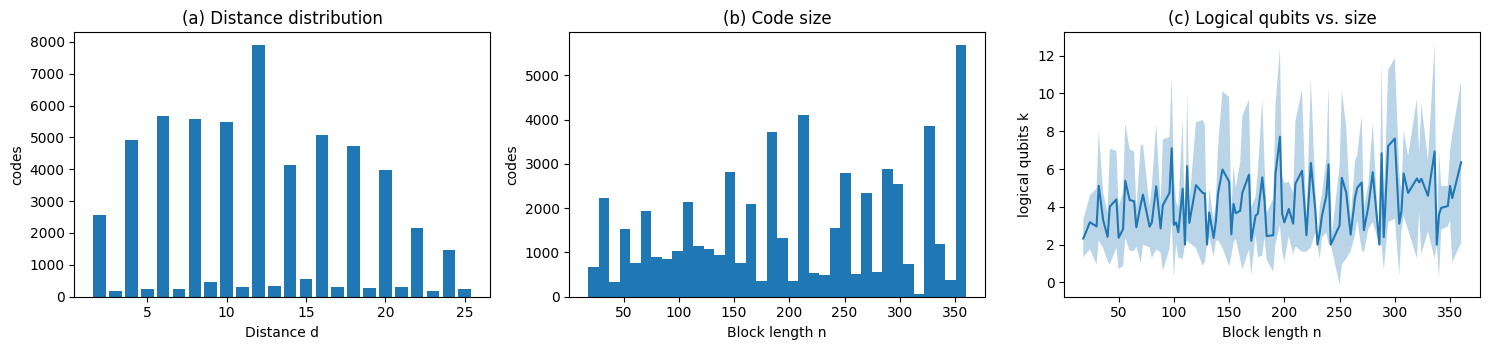

라벨(최솟값)을 찾아낸 방법별 코드 수: {'RIS': 47794, 'QDistRndMW': 54312, 'QDistEvol': 54933}


In [13]:
import collections, numpy as np, pandas as pd, matplotlib.pyplot as plt
import bbrepro as R

def load_json(name):
    for d in (WORK_DIR, DRIVE_DIR):
        if d and os.path.exists(os.path.join(d, name)):
            return json.load(open(os.path.join(d, name)))
    raise FileNotFoundError(name)

DATA = load_json("dataset.json")
SPLIT = {s: [r for r in DATA if r["split"] == s] for s in ("train", "val", "test")}
d_all = np.array([r["d"] for r in DATA]); n_all = np.array([2 * r["l"] * r["m"] for r in DATA])
k_all = np.array([r["k"] for r in DATA]); pbb = np.array([bool(r["C"]) for r in DATA])
summary = pd.DataFrame({
    "논문": ["58,704", "83.9% / 16.1%", "18 – 360", "[3, 30]", "2 – 216", "0.006 – 0.750", "12", "2 – 25"],
    "재현": [f"{len(DATA):,}", f"{100*(~pbb).mean():.1f}% / {100*pbb.mean():.1f}%", f"{n_all.min()} – {n_all.max()}",
            f"[{min(min(r['l'], r['m']) for r in DATA)}, {max(max(r['l'], r['m']) for r in DATA)}]",
            f"{k_all.min()} – {k_all.max()}", f"{(k_all/n_all).min():.3f} – {(k_all/n_all).max():.3f}",
            f"{np.median(d_all):g}", f"{d_all.min()} – {d_all.max()}"]},
    index=["코드 수", "CSS / PBB", "n 범위", "ℓ, m 범위", "k 범위", "부호율 k/n", "거리 중앙값", "거리 범위"])
display(summary)
print({s: len(v) for s, v in SPLIT.items()})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
c = collections.Counter(d_all.tolist()); ax[0].bar(list(c), list(c.values()))
ax[0].set(title="(a) Distance distribution", xlabel="Distance d", ylabel="codes")
ax[1].hist(n_all, bins=36); ax[1].set(title="(b) Code size", xlabel="Block length n", ylabel="codes")
ns = np.unique(n_all); mk = np.array([k_all[n_all == v].mean() for v in ns]); sk = np.array([k_all[n_all == v].std() for v in ns])
ax[2].plot(ns, mk); ax[2].fill_between(ns, mk - sk, mk + sk, alpha=.3)
ax[2].set(title="(c) Logical qubits vs. size", xlabel="Block length n", ylabel="logical qubits k")
plt.tight_layout(); plt.show()

win = collections.Counter()
for r in DATA:
    for mth, (d, ok, _) in (r.get("label_methods") or {}).items():
        if ok and d == r["d"]: win[mth] += 1
print("라벨(최솟값)을 찾아낸 방법별 코드 수:", dict(win))

## 6. 백그라운드 CPU 단계 시작

테스트셋에 대한 6개 휴리스틱 벤치마크(표 1), 정확한 거리 인증(표 2·3), 표 7 코드 계산을 하나의 백그라운드 프로세스로 시작합니다. 학습용 CPU 워커를 남겨 두도록 프로세스 수를 줄여서 돌립니다. 세션이 끊겼다면 이 셀을 다시 실행하면 이어서 진행합니다. 진행 상황은 다음 셀로 확인하세요.

In [14]:
import shlex
BG_LOG = os.path.join(WORK_DIR, "background.log")
def bg_running():
    return subprocess.run(["pgrep", "-f", "bbstages.py (bench|cert|table7)"], capture_output=True).returncode == 0
if bg_running():
    print("백그라운드 단계가 이미 실행 중입니다.")
else:
    if os.path.exists(BG_LOG):
        os.replace(BG_LOG, BG_LOG + ".old")   # 이전 실행의 완료 표시(__DONE__)가 새 실행에 섞이지 않도록
    cmd = " && ".join(f"{shlex.quote(PY)} bbstages.py {s} --config {CFG_BG_PATH}" for s in ("bench", "cert", "table7"))
    BG = subprocess.Popen(["bash", "-c", f"({cmd}) >> {BG_LOG} 2>&1; echo __DONE__ >> {BG_LOG}"],
                          cwd=REPO_DIR, start_new_session=True)
    print("시작:", cmd)

시작: /usr/bin/python3 bbstages.py bench --config /content/bbnet_work/cfg_bg.json && /usr/bin/python3 bbstages.py cert --config /content/bbnet_work/cfg_bg.json && /usr/bin/python3 bbstages.py table7 --config /content/bbnet_work/cfg_bg.json


In [15]:
!tail -n 4 {BG_LOG}

## 7. BB-Net 학습 (논문 표 6)

검증 NLL이 가장 낮은 에폭의 가중치를 `best.pt`로 저장합니다. 학습률은 9 에폭 선형 워밍업 뒤 코사인 감쇠로 두었습니다(논문은 워밍업 뒤 일정을 명시하지 않음). Gradient clipping 1.0과 bf16 AMP도 논문에 명시되지 않은 선택입니다.

In [16]:
import bbtrain as T
MAIN_RUN = os.path.join(RUNS, "main_" + T.run_name(True, True, True, True, 0))
hist_main = T.train_run(MAIN_RUN, SPLIT["train"], SPLIT["val"], tanner=True, film=True, augment=True, canon=True,
                        depth=TRAIN["depth"], width=TRAIN["width"], epochs=TRAIN["epochs"],
                        warmup_epochs=TRAIN["warmup_epochs"], batch=TRAIN["batch"], lr=TRAIN["lr"], wd=TRAIN["wd"],
                        seed=0, num_workers=TRAIN_WORKERS)

[main_tanner_aug1_canon1_film1_s0] 이미 90 에폭 완료 — 건너뜀


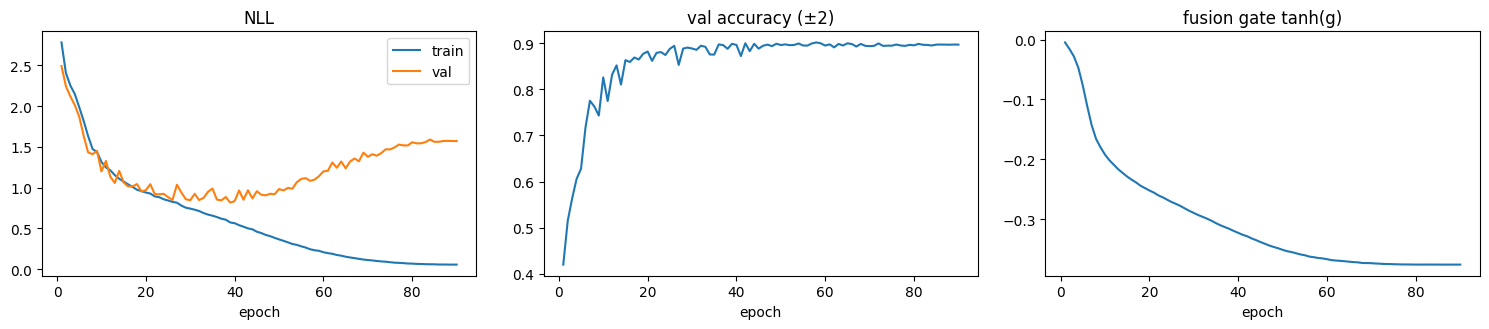

{'epoch': 39.0, 'train_loss': 0.5738, 'val_nll': 0.8167, 'val_acc2': 0.899, 'val_exact': 0.7091, 'val_rmse': 1.935, 'lr': 0.0002, 'gate': -0.32, 'sec': 18.271}


In [17]:
H = pd.DataFrame(hist_main)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot(H.epoch, H.train_loss, label="train"); ax[0].plot(H.epoch, H.val_nll, label="val"); ax[0].set(title="NLL", xlabel="epoch"); ax[0].legend()
ax[1].plot(H.epoch, H.val_acc2); ax[1].set(title="val accuracy (±2)", xlabel="epoch")
ax[2].plot(H.epoch, H.gate); ax[2].set(title="fusion gate tanh(g)", xlabel="epoch")
plt.tight_layout(); plt.show()
print(H.loc[H.val_nll.idxmin()].round(4).to_dict())

## 8. Ablation (논문 표 5, 그림 5)

논문 표기와 같이 **BB-Net** = Tanner 가지가 없는 다항식 전용 모델(L=16), **BB-Net-Tanner** = 두 가지를 모두 쓰는 모델(L=8)입니다. 5개 구성 × 2개 모델 × 시드 수만큼 학습하고, 각 실행의 최고 검증 NLL을 평균 ± 표준편차로 보고합니다. 전체 구성의 BB-Net-Tanner 시드 0은 §7의 주 모델과 설정이 같으면 그 결과를 재사용합니다. GPU 시간이 가장 많이 드는 절이므로, 먼저 표 1–4를 보고 싶다면 `ABLATION["run"] = False`로 건너뛰었다가 나중에 돌리세요.

In [18]:
ABL_ROWS = [(False, False, True), (True, False, True), (False, True, True), (True, True, False), (True, True, True)]
same_as_main = (ABLATION["epochs"] == TRAIN["epochs"] and ABLATION["depth_tanner"] == TRAIN["depth"]
                and ABLATION["width"] == TRAIN["width"])
def abl_dir(tanner, aug, canon, film, seed):
    if tanner and aug and canon and film and seed == 0 and same_as_main:
        return MAIN_RUN
    return os.path.join(RUNS, "ablation", T.run_name(tanner, aug, canon, film, seed))

if ABLATION["run"]:
    for seed in ABLATION["seeds"]:
        for tanner in (False, True):
            for aug, canon, film in ABL_ROWS:
                T.train_run(abl_dir(tanner, aug, canon, film, seed), SPLIT["train"], SPLIT["val"],
                            tanner=tanner, film=film, augment=aug, canon=canon,
                            depth=ABLATION["depth_tanner" if tanner else "depth_poly"], width=ABLATION["width"],
                            epochs=ABLATION["epochs"], warmup_epochs=max(1, ABLATION["epochs"] // 10),
                            batch=TRAIN["batch"], lr=TRAIN["lr"], wd=TRAIN["wd"], seed=seed, num_workers=TRAIN_WORKERS,
                            need_best=False)

[poly_aug0_canon0_film1_s0] 이미 90 에폭 완료 — 건너뜀
[poly_aug1_canon0_film1_s0] 이미 90 에폭 완료 — 건너뜀
[poly_aug0_canon1_film1_s0] 이미 90 에폭 완료 — 건너뜀
[poly_aug1_canon1_film0_s0] 이미 90 에폭 완료 — 건너뜀
[poly_aug1_canon1_film1_s0] 이미 90 에폭 완료 — 건너뜀
[tanner_aug0_canon0_film1_s0] 이미 90 에폭 완료 — 건너뜀
[tanner_aug1_canon0_film1_s0] 이미 90 에폭 완료 — 건너뜀
[tanner_aug0_canon1_film1_s0] 이미 90 에폭 완료 — 건너뜀
[tanner_aug1_canon1_film0_s0] 이미 90 에폭 완료 — 건너뜀
[main_tanner_aug1_canon1_film1_s0] 이미 90 에폭 완료 — 건너뜀
[poly_aug0_canon0_film1_s1] 이미 90 에폭 완료 — 건너뜀
[poly_aug1_canon0_film1_s1] 이미 90 에폭 완료 — 건너뜀
[poly_aug0_canon1_film1_s1] 이미 90 에폭 완료 — 건너뜀
[poly_aug1_canon1_film0_s1] 이미 90 에폭 완료 — 건너뜀
[poly_aug1_canon1_film1_s1] 이미 90 에폭 완료 — 건너뜀
[tanner_aug0_canon0_film1_s1] 이미 90 에폭 완료 — 건너뜀
[tanner_aug1_canon0_film1_s1] 이미 90 에폭 완료 — 건너뜀
[tanner_aug0_canon1_film1_s1] 이미 90 에폭 완료 — 건너뜀
[tanner_aug1_canon1_film0_s1] 이미 90 에폭 완료 — 건너뜀
[tanner_aug1_canon1_film1_s1] 이미 90 에폭 완료 — 건너뜀
[poly_aug0_canon0_film1_s2] 이미 90 에폭 완료 — 건너뜀
[poly_aug

표 5: 검증셋 최고 에폭 NLL (낮을수록 좋음)


,Aug.,Shift-Canon,FiLM,BB-Net (재현),BB-Net (논문),BB-Net-Tanner (재현),BB-Net-Tanner (논문)
0,×,×,✓,1.669 ± 0.019 (n=3),1.496 ± 0.014,1.103 ± 0.013 (n=3),1.039 ± 0.019
1,✓,×,✓,1.512 ± 0.015 (n=3),1.436 ± 0.014,0.840 ± 0.020 (n=3),0.762 ± 0.012
2,×,✓,✓,1.607 ± 0.022 (n=3),1.409 ± 0.013,1.043 ± 0.014 (n=3),0.924 ± 0.026
3,✓,✓,×,1.387 ± 0.003 (n=3),1.217 ± 0.006,0.820 ± 0.002 (n=3),0.712 ± 0.025
4,✓,✓,✓,1.316 ± 0.004 (n=3),1.157 ± 0.001,0.803 ± 0.012 (n=3),0.683 ± 0.010


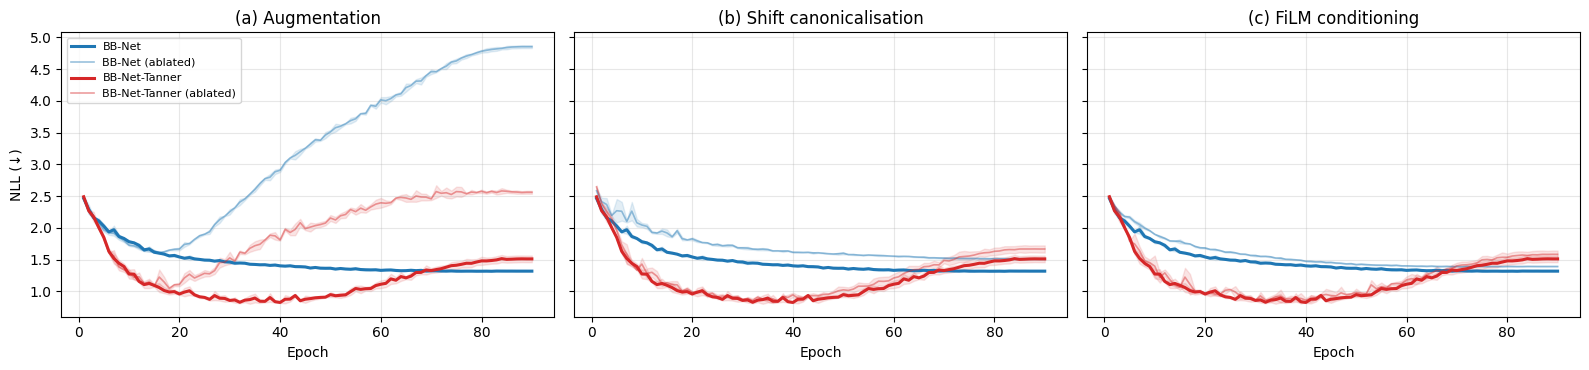

In [19]:
PAPER_T5 = {(False, False, True): ("1.496 ± 0.014", "1.039 ± 0.019"), (True, False, True): ("1.436 ± 0.014", "0.762 ± 0.012"),
            (False, True, True): ("1.409 ± 0.013", "0.924 ± 0.026"), (True, True, False): ("1.217 ± 0.006", "0.712 ± 0.025"),
            (True, True, True): ("1.157 ± 0.001", "0.683 ± 0.010")}
def histories(tanner, aug, canon, film):
    out = []
    for s in ABLATION["seeds"]:
        p = os.path.join(abl_dir(tanner, aug, canon, film, s), "history.json")
        if os.path.exists(p): out.append(json.load(open(p)))
    return out
rows = []
for aug, canon, film in ABL_ROWS:
    row = {"Aug.": "✓" if aug else "×", "Shift-Canon": "✓" if canon else "×", "FiLM": "✓" if film else "×"}
    for tanner, nm in ((False, "BB-Net"), (True, "BB-Net-Tanner")):
        best = [min(h["val_nll"] for h in hs) for hs in histories(tanner, aug, canon, film) if hs]
        row[f"{nm} (재현)"] = f"{np.mean(best):.3f} ± {np.std(best):.3f} (n={len(best)})" if best else "—"
        row[f"{nm} (논문)"] = PAPER_T5[(aug, canon, film)][int(tanner)]
    rows.append(row)
print("표 5: 검증셋 최고 에폭 NLL (낮을수록 좋음)")
display(pd.DataFrame(rows))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for a, (title, abl) in zip(ax, [("(a) Augmentation", (False, True, True)), ("(b) Shift canonicalisation", (True, False, True)),
                                ("(c) FiLM conditioning", (True, True, False))]):
    for tanner, col, nm in ((False, "tab:blue", "BB-Net"), (True, "tab:red", "BB-Net-Tanner")):
        for cfg_, lw, alpha, suf in (((True, True, True), 2.2, 1.0, ""), (abl, 1.2, .45, " (ablated)")):
            hs = histories(tanner, *cfg_)
            if not hs: continue
            L = min(len(h) for h in hs)
            Y = np.array([[e["val_nll"] for e in h[:L]] for h in hs]); x = np.arange(1, L + 1)
            a.plot(x, Y.mean(0), color=col, lw=lw, alpha=alpha, label=nm + suf)
            if len(hs) > 1: a.fill_between(x, Y.mean(0) - Y.std(0), Y.mean(0) + Y.std(0), color=col, alpha=.12)
    a.set(title=title, xlabel="Epoch"); a.grid(alpha=.3)
ax[0].set_ylabel("NLL (↓)"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 9. 테스트 벤치마크 (논문 표 1–4, 그림 4)

백그라운드 단계가 끝날 때까지 기다립니다(10분마다 진행 상황 출력). 정확도는 논문처럼 기준 거리 ±2 허용이며, witness가 식 (4)를 만족하지 않는 휴리스틱 결과는 오답으로 셉니다. RMSE는 반환된 값을 그대로 쓰고(시간 초과·오류는 0), 논문이 이 경우를 어떻게 처리했는지는 명시되어 있지 않습니다. CSS 코드의 휴리스틱은 Z 성분만 계산합니다(BB 코드는 $d_X = d_Z$).

In [20]:
import time
def last_log_line():
    try:
        lines = open(BG_LOG).read().strip().splitlines()
    except FileNotFoundError:
        return "(로그 파일 없음)"
    return lines[-1][:160] if lines else "(아직 출력 없음 — 시작 중)"
def bg_done():
    return os.path.exists(BG_LOG) and "__DONE__" in open(BG_LOG).read()
while not bg_done():                     # 완료 표시가 로그에 찍히면 바로 끝낸다
    if not bg_running():
        print("백그라운드 프로세스가 없습니다 (세션 재시작?). §6 셀을 다시 실행하세요."); break
    if int(time.time()) % 600 < 30: print(time.strftime("%H:%M"), last_log_line())
    time.sleep(30)
print("완료")

완료


In [21]:
def load_store(name):
    out = {}
    for d in (DRIVE_DIR, WORK_DIR):
        p = d and os.path.join(d, name)
        if p and os.path.exists(p):
            for line in open(p):
                try: k, v = json.loads(line); out[k] = v
                except Exception: pass
    return out

BENCH, CERT = load_store("bench.jsonl"), load_store("cert.jsonl")
TEST = SPLIT["test"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, ck = T.load_best(MAIN_RUN, device)
codes_test = [R.code_from_record(r) for r in TEST]
T.predict_proba(model, codes_test[:256], device)                 # 워밍업
PROBS, bb_sec = T.predict_proba(model, codes_test, device)
PRED = PROBS.argmax(1) + 2
REF = np.array([r["d"] for r in TEST])
print(f"BB-Net (epoch {ck['epoch']}) 테스트 {len(TEST):,}개: 총 {bb_sec:.1f}s, 코드당 {bb_sec/len(TEST):.4f}s")

def heur(name, idx):
    m, trials = R.BENCH_METHODS[name]
    d, ok, sec = [], [], []
    for i in idx:
        v = BENCH.get(f"{name}|{TEST[i]['key']}")
        if v is None or "status" in v:
            d.append(0); ok.append(False); sec.append(CFG["bench_timeout"] if v and v.get("status") == "timeout" else 0.0)
        else:
            d.append(v["d"]); ok.append(v["valid"]); sec.append(v["sec"])
    return np.array(d), np.array(ok), np.array(sec), trials

METHODS = [m for m in ["QDistRnd", "QDistEvol", "BP-OSD", "GEStim", "CCStim", "UEStim"] if m in CFG["bench_methods"]]
BIDX = np.array([i for i, r in enumerate(TEST) if all(f"{m}|{r['key']}" in BENCH for m in METHODS)])
print(f"모든 휴리스틱 결과가 있는 테스트 코드: {len(BIDX):,}개")

def table(idx, ref, paper):
    cols = {}
    for m in METHODS:
        d, ok, sec, tr = heur(m, idx)
        cols[m] = [tr, sec.mean(), sec.sum(), np.sqrt(((d - ref) ** 2).mean()), 100 * (ok & (np.abs(d - ref) <= 2)).mean(), 100 * ok.mean()]
    p = PRED[idx]
    cols["BB-Net"] = [1, bb_sec / len(TEST), bb_sec / len(TEST) * len(idx), np.sqrt(((p - ref) ** 2).mean()),
                      100 * (np.abs(p - ref) <= 2).mean(), 100.0]
    df = pd.DataFrame(cols, index=["Trials Per Code", "Time Per Code [s]", "Total Time [s]", "RMSE", "Accuracy (±2) [%]", "유효 출력 [%]"])
    pp = pd.DataFrame({k: v for k, v in paper.items() if k in df.columns},
                      index=["Trials Per Code", "Time Per Code [s]", "Total Time [s]", "RMSE", "Accuracy (±2) [%]"])
    return df.round(3), pp

BB-Net (epoch 39) 테스트 5,723개: 총 3.5s, 코드당 0.0006s
모든 휴리스틱 결과가 있는 테스트 코드: 5,723개


In [22]:
PAPER_T1 = {"QDistRnd": [200, 3.3, 19383, 2.319, 92.20], "QDistEvol": [200, 1.0, 6057, 1.485, 94.86],
            "BP-OSD": [200, 19.1, 112275, 23.322, 82.23], "GEStim": [1, 1.2, 6940, 4.950, 0.02],
            "CCStim": [1, 1.2, 7164, 9.309, 34.60], "UEStim": [3, 13.1, 76775, 1.933, 61.23], "BB-Net": [1, 0.005, 26.8, 1.131, 96.39]}
ours, paper = table(BIDX, REF[BIDX], PAPER_T1)
print(f"표 1: 테스트 벤치마크 ({len(BIDX):,}개 코드) — 재현"); display(ours)
print("표 1 — 논문 (5,870개)"); display(paper)
print(f"BB-Net 테스트셋 전체 ({len(TEST):,}개): 정확도(±2) {100*(np.abs(PRED-REF)<=2).mean():.2f}%, "
      f"RMSE {np.sqrt(((PRED-REF)**2).mean()):.3f}, 정확히 일치 {100*(PRED==REF).mean():.2f}%")

표 1: 테스트 벤치마크 (5,723개 코드) — 재현


,QDistRnd,QDistEvol,BP-OSD,GEStim,CCStim,UEStim,BB-Net
Trials Per Code,200.000,200.000,200.000,1.000,1.000,3.000,1.000
Time Per Code [s],0.279,0.313,2.766,0.041,0.050,97.060,0.001
Total Time [s],1599.492,1793.203,15829.615,233.308,284.303,555476.017,3.505
RMSE,2.181,2.463,2.486,15.033,13.126,7.251,1.873
Accuracy (±2) [%],92.294,90.704,90.914,0.979,26.140,84.396,90.302
유효 출력 [%],100.000,100.000,99.266,2.499,37.812,91.892,100.000


표 1 — 논문 (5,870개)


,QDistRnd,QDistEvol,BP-OSD,GEStim,CCStim,UEStim,BB-Net
Trials Per Code,200.000,200.000,200.000,1.00,1.000,3.000,1.000
Time Per Code [s],3.300,1.000,19.100,1.20,1.200,13.100,0.005
Total Time [s],19383.000,6057.000,112275.000,6940.00,7164.000,76775.000,26.800
RMSE,2.319,1.485,23.322,4.95,9.309,1.933,1.131
Accuracy (±2) [%],92.200,94.860,82.230,0.02,34.600,61.230,96.390


BB-Net 테스트셋 전체 (5,723개): 정확도(±2) 90.30%, RMSE 1.873, 정확히 일치 71.26%


### 인증된 거리와 상한 부분집합 (표 2·3)

정확한 거리 인증이 끝난(최적성이 증명된) 코드를 인증 부분집합으로, 나머지 시도한 코드를 상한 부분집합으로 둡니다. 인증 부분집합의 기준값은 인증된 거리입니다. 논문은 인증된 모든 코드에서 라벨이 인증된 거리와 같았다고 보고했으므로, 우리 라벨의 일치율도 함께 확인합니다.

In [23]:
att = [i for i in BIDX if TEST[i]["key"] in CERT]
cidx = np.array([i for i in att if CERT[TEST[i]["key"]].get("status") == "OPTIMAL"], dtype=int)
uidx = np.array([i for i in att if CERT[TEST[i]["key"]].get("status") != "OPTIMAL"], dtype=int)
cref = np.array([CERT[TEST[i]["key"]]["d"] for i in cidx])
n_skip = sum(CERT[TEST[i]["key"]].get("status") == "SKIPPED" for i in att)
print(f"인증 대상 {len(att):,}개 (라벨 거리 > {CFG.get('cert_skip_above')} 로 생략 {n_skip:,}개 포함) 중 인증 {len(cidx):,}개 "
      f"(논문: 5,870개 중 2,366개, 코드당 2시간 제한) | "
      f"인증 코드 최대 거리 {cref.max() if len(cref) else '-'} (논문: 14)")
if len(cidx):
    agree = (REF[cidx] == cref).mean()
    print(f"라벨 = 인증 거리 인 비율: {100*agree:.2f}% (논문: 100%) | 라벨 > 인증 거리: {(REF[cidx] > cref).sum()}개")
PAPER_T2 = {"QDistRnd": [200, 5.0, 11887, 0.000, 100.00], "QDistEvol": [200, 1.6, 3883, 0.000, 100.00],
            "BP-OSD": [200, 3.8, 9032, 0.699, 99.96], "GEStim": [1, 1.0, 2406, 11.453, 0.04], "CCStim": [1, 1.0, 2407, 7.434, 64.03],
            "UEStim": [3, 2.1, 4898, 2.641, 98.44], "BB-Net": [1, 0.005, 10.8, 0.594, 98.94]}
PAPER_T3 = {"QDistRnd": [200, 2.1, 7496, 3.002, 86.93], "QDistEvol": [200, 0.6, 2175, 1.923, 91.38],
            "BP-OSD": [200, 29.5, 103243, 30.181, 70.26], "GEStim": [1, 1.3, 4535, 42.355, 0.00], "CCStim": [1, 1.4, 4758, 35.362, 14.73],
            "UEStim": [3, 20.5, 71877, 37.190, 36.10], "BB-Net": [1, 0.005, 16.0, 1.380, 94.66]}
for title, idx, ref, pp in (("표 2: 인증된 거리 코드", cidx, cref, PAPER_T2), ("표 3: 상한 거리 코드", uidx, REF[uidx] if len(uidx) else [], PAPER_T3)):
    if len(idx):
        o, p = table(idx, np.asarray(ref), pp)
        print(f"{title} ({len(idx):,}개) — 재현"); display(o); print("논문"); display(p)

인증 대상 5,723개 (라벨 거리 > 14 로 생략 1,567개 포함) 중 인증 1,445개 (논문: 5,870개 중 2,366개, 코드당 2시간 제한) | 인증 코드 최대 거리 9 (논문: 14)
라벨 = 인증 거리 인 비율: 100.00% (논문: 100%) | 라벨 > 인증 거리: 0개
표 2: 인증된 거리 코드 (1,445개) — 재현


,QDistRnd,QDistEvol,BP-OSD,GEStim,CCStim,UEStim,BB-Net
Trials Per Code,200.000,200.000,200.000,1.000,1.000,3.000,1.000
Time Per Code [s],0.296,0.325,1.463,0.031,0.036,0.100,0.001
Total Time [s],428.025,469.466,2114.186,44.751,52.315,144.195,0.885
RMSE,0.000,0.000,0.373,5.957,4.668,0.952,0.906
Accuracy (±2) [%],100.000,100.000,99.792,2.284,70.035,98.962,97.924
유효 출력 [%],100.000,100.000,100.000,3.875,77.716,99.931,100.000


논문


,QDistRnd,QDistEvol,BP-OSD,GEStim,CCStim,UEStim,BB-Net
Trials Per Code,200.0,200.0,200.000,1.000,1.000,3.000,1.000
Time Per Code [s],5.0,1.6,3.800,1.000,1.000,2.100,0.005
Total Time [s],11887.0,3883.0,9032.000,2406.000,2407.000,4898.000,10.800
RMSE,0.0,0.0,0.699,11.453,7.434,2.641,0.594
Accuracy (±2) [%],100.0,100.0,99.960,0.040,64.030,98.440,98.940


표 3: 상한 거리 코드 (4,278개) — 재현


,QDistRnd,QDistEvol,BP-OSD,GEStim,CCStim,UEStim,BB-Net
Trials Per Code,200.000,200.000,200.000,1.000,1.000,3.000,1.000
Time Per Code [s],0.274,0.309,3.206,0.044,0.054,129.811,0.001
Total Time [s],1171.467,1323.736,13715.428,188.557,231.988,555331.822,2.620
RMSE,2.522,2.848,2.867,17.040,14.938,8.369,2.101
Accuracy (±2) [%],89.691,87.564,87.915,0.538,11.314,79.476,87.728
유효 출력 [%],100.000,100.000,99.018,2.034,24.334,89.177,100.000


논문


,QDistRnd,QDistEvol,BP-OSD,GEStim,CCStim,UEStim,BB-Net
Trials Per Code,200.000,200.000,200.000,1.000,1.000,3.00,1.000
Time Per Code [s],2.100,0.600,29.500,1.300,1.400,20.50,0.005
Total Time [s],7496.000,2175.000,103243.000,4535.000,4758.000,71877.00,16.000
RMSE,3.002,1.923,30.181,42.355,35.362,37.19,1.380
Accuracy (±2) [%],86.930,91.380,70.260,0.000,14.730,36.10,94.660


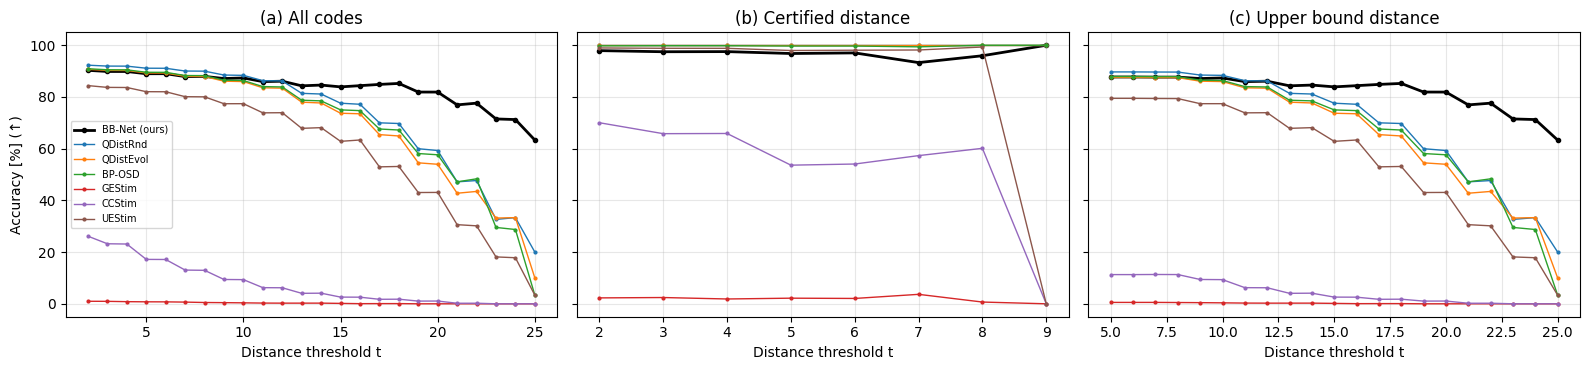

In [24]:
def acc_curve(pred, ok, ref, ts):
    return [100 * (ok[ref >= t] & (np.abs(pred[ref >= t] - ref[ref >= t]) <= 2)).mean() if (ref >= t).any() else np.nan for t in ts]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
panels = [("(a) All codes", BIDX, REF[BIDX], range(2, 26)), ("(b) Certified distance", cidx, cref, range(2, 15)),
          ("(c) Upper bound distance", uidx, REF[uidx] if len(uidx) else np.array([]), range(5, 26))]
for a, (title, idx, ref, ts) in zip(ax, panels):
    if len(idx) == 0: a.set(title=title + " (no data)"); continue
    ts = list(ts); ref = np.asarray(ref)
    a.plot(ts, acc_curve(PRED[idx], np.ones(len(idx), bool), ref, ts), "k-o", ms=3, lw=2, label="BB-Net (ours)")
    for m in METHODS:
        d, ok, _, _ = heur(m, idx)
        a.plot(ts, acc_curve(d, ok, ref, ts), "-o", ms=2, lw=1, label=m)
    a.set(title=title, xlabel="Distance threshold t"); a.grid(alpha=.3)
ax[0].set_ylabel("Accuracy [%] (↑)"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

In [25]:
def auc(score, y):
    # Mann–Whitney U 기반 ROC-AUC (동점은 평균 순위)
    y = np.asarray(y, bool); s = np.asarray(score, float)
    if y.all() or (~y).all(): return np.nan
    order = np.argsort(s, kind="mergesort"); ranks = np.empty(len(s)); ranks[order] = np.arange(1, len(s) + 1)
    for v in np.unique(s):
        m = s == v
        if m.sum() > 1: ranks[m] = ranks[m].mean()
    npos = y.sum(); return (ranks[y].sum() - npos * (npos + 1) / 2) / (npos * (~y).sum())

TS = [4, 8, 10, 12, 14, 16, 18, 20, 22, 24]
ref = REF[BIDX]; rows = {}
rows["BB-Net"] = [auc(PROBS[BIDX][:, t - 2:].sum(1), ref >= t) for t in TS]
for m in METHODS:
    d, ok, _, _ = heur(m, BIDX)
    rows[m] = [auc(np.where(ok, d, -1), ref >= t) for t in TS]     # 실패한 출력은 가장 낮은 점수
PAPER_T4 = {"BB-Net": [1.000, .998, .996, .993, .989, .989, .988, .987, .990, .991],
            "QDistEvol": [1.000, 1.000, 1.000, 1.000, .999, .998, .998, .995, .991, .992],
            "QDistRnd": [1.000, 1.000, 1.000, 1.000, 1.000, .998, .997, .993, .991, .990],
            "BP-OSD": [1.000, 1.000, 1.000, .997, .987, .967, .950, .936, .931, .926],
            "UEStim": [.996, .996, .997, .992, .974, .944, .917, .900, .890, .883],
            "GEStim": [.998, .946, .913, .892, .876, .871, .855, .849, .845, .845],
            "CCStim": [.991, .973, .934, .924, .908, .909, .895, .889, .884, .893]}
cols = [f"d≥{t}" for t in TS]
print("표 4: 거리 스크리닝 ROC-AUC — 재현"); display(pd.DataFrame(rows, index=cols).T.round(3))
print("논문"); display(pd.DataFrame(PAPER_T4, index=cols).T)
alt = {}
for m in METHODS:
    d, ok, _, _ = heur(m, BIDX)
    alt[f"{m} (실패 = 최고 점수)"] = [auc(np.where(ok, d, 10**6), ref >= t) for t in TS]
    alt[f"{m} (반환값 그대로)"] = [auc(d, ref >= t) for t in TS]
print("참고: 휴리스틱 실패 출력의 점수를 다르게 매긴 경우 (논문은 처리 방식을 밝히지 않음. 위 표는 실패 = 최저 점수)")
display(pd.DataFrame(alt, index=cols).T.round(3))

표 4: 거리 스크리닝 ROC-AUC — 재현


,d≥4,d≥8,d≥10,d≥12,d≥14,d≥16,d≥18,d≥20,d≥22,d≥24
BB-Net,1.000,0.998,0.995,0.993,0.988,0.987,0.984,0.978,0.979,0.977
QDistRnd,1.000,1.000,1.000,1.000,1.000,0.998,0.995,0.990,0.986,0.986
QDistEvol,1.000,1.000,1.000,1.000,0.999,0.996,0.994,0.988,0.983,0.983
BP-OSD,0.992,0.990,0.988,0.987,0.985,0.984,0.986,0.980,0.974,0.968
GEStim,0.488,0.490,0.490,0.490,0.491,0.487,0.489,0.490,0.493,0.487
CCStim,0.388,0.340,0.343,0.334,0.342,0.338,0.337,0.336,0.325,0.325
UEStim,0.915,0.891,0.870,0.844,0.786,0.737,0.652,0.574,0.495,0.460


논문


,d≥4,d≥8,d≥10,d≥12,d≥14,d≥16,d≥18,d≥20,d≥22,d≥24
BB-Net,1.000,0.998,0.996,0.993,0.989,0.989,0.988,0.987,0.990,0.991
QDistEvol,1.000,1.000,1.000,1.000,0.999,0.998,0.998,0.995,0.991,0.992
QDistRnd,1.000,1.000,1.000,1.000,1.000,0.998,0.997,0.993,0.991,0.990
BP-OSD,1.000,1.000,1.000,0.997,0.987,0.967,0.950,0.936,0.931,0.926
UEStim,0.996,0.996,0.997,0.992,0.974,0.944,0.917,0.900,0.890,0.883
GEStim,0.998,0.946,0.913,0.892,0.876,0.871,0.855,0.849,0.845,0.845
CCStim,0.991,0.973,0.934,0.924,0.908,0.909,0.895,0.889,0.884,0.893


참고: 휴리스틱 실패 출력의 점수를 다르게 매긴 경우 (논문은 처리 방식을 밝히지 않음. 위 표는 실패 = 최저 점수)


,d≥4,d≥8,d≥10,d≥12,d≥14,d≥16,d≥18,d≥20,d≥22,d≥24
QDistRnd (실패 = 최고 점수),1.000,1.000,1.000,1.000,1.000,0.998,0.995,0.990,0.986,0.986
QDistRnd (반환값 그대로),1.000,1.000,1.000,1.000,1.000,0.998,0.995,0.990,0.986,0.986
QDistEvol (실패 = 최고 점수),1.000,1.000,1.000,1.000,0.999,0.996,0.994,0.988,0.983,0.983
QDistEvol (반환값 그대로),1.000,1.000,1.000,1.000,0.999,0.996,0.994,0.988,0.983,0.983
BP-OSD (실패 = 최고 점수),0.999,0.999,1.000,0.999,0.996,0.992,0.988,0.981,0.975,0.978
BP-OSD (반환값 그대로),0.999,0.999,1.000,1.000,0.999,0.996,0.993,0.987,0.981,0.984
GEStim (실패 = 최고 점수),0.513,0.510,0.510,0.510,0.509,0.513,0.512,0.511,0.508,0.513
GEStim (반환값 그대로),0.488,0.490,0.490,0.490,0.491,0.487,0.489,0.490,0.493,0.487
CCStim (실패 = 최고 점수),0.925,0.844,0.794,0.768,0.728,0.717,0.703,0.692,0.690,0.686
CCStim (반환값 그대로),0.387,0.340,0.343,0.334,0.342,0.337,0.337,0.336,0.325,0.325


## 10. 표 7: 휴리스틱이 거리를 과대평가하는 코드들

논문에 적힌 다항식을 그대로 씁니다. 이 코드들(과 대칭 궤도)은 학습 데이터에서 제외했으므로 BB-Net에게는 처음 보는 코드입니다. "기준"은 우리 라벨 방법(`t7_label_preset`)의 최솟값이고, 휴리스틱은 논문 표 1과 같은 200회입니다.

In [26]:
T7 = load_store("table7.jsonl")
def t7_label(i):   # 기준 거리 = 유효한 결과의 최솟값 (방법별 항목 {i}|label:<방법> 과 예전 형식 {i}|label 모두 읽음)
    old = T7.get(f"{i}|label") or {}
    vals = [old["d"]] if old.get("d") else []
    vals += [v["d"] for k, v in T7.items() if k.startswith(f"{i}|label:") and v and v.get("valid") and v.get("d", 0) > 0]
    return min(vals) if vals else None
t7 = R.table7_codes()
P7, _ = T.predict_proba(model, [c for c, _ in t7], device)
rows = []
for i, (c, (gt, bp, qe, qr, bbn)) in enumerate(t7):
    if not any(k.startswith(f"{i}|") for k in T7): continue
    def g(m):
        v = T7.get(f"{i}|{m}")
        if v is None: return "—"                       # 실행하지 않음 (t7_methods 에 없음)
        return "Fail" if "status" in v or not v["valid"] else v["d"]
    rows.append({"(n, ℓ, m)": f"({c.n}, {c.ell}, {c.m})", "PBB": "" if c.is_css else "✓", "k": c.k,
                 "GT 논문": gt, "기준 재현": t7_label(i),
                 "BP-OSD 논문/재현": f"{bp or 'Fail'} / {g('BP-OSD')}", "QDistEvol 논문/재현": f"{qe} / {g('QDistEvol')}",
                 "QDistRnd 논문/재현": f"{qr} / {g('QDistRnd')}", "BB-Net 논문/재현": f"{bbn} / {P7[i].argmax() + 2}"})
display(pd.DataFrame(rows))
if rows:
    gt = np.array([r["GT 논문"] for r in rows]); pb = np.array([int(r["BB-Net 논문/재현"].split(" / ")[1]) for r in rows])
    print(f"재현 BB-Net 대 논문 GT: 정확히 일치 {(pb == gt).sum()}/{len(rows)}, ±2 이내 {(abs(pb - gt) <= 2).sum()}/{len(rows)} "
          "(논문 표 7 은 BB-Net 이 맞힌 코드를 골라 놓은 것이라 논문 쪽은 전부 일치)")

,"(n, ℓ, m)",PBB,k,GT 논문,기준 재현,BP-OSD 논문/재현,QDistEvol 논문/재현,QDistRnd 논문/재현,BB-Net 논문/재현
0,"(324, 18, 9)",,2,18,18,44 / 34,45 / 47,18 / 28,18 / 18
1,"(270, 27, 5)",,2,25,27,35 / 39,38 / 36,37 / 35,25 / 25
2,"(342, 19, 9)",✓,2,24,24,Fail / Fail,36 / 32,26 / 26,24 / 22
3,"(348, 29, 6)",✓,4,24,26,Fail / Fail,36 / 34,44 / 34,24 / 22
4,"(272, 17, 8)",,4,25,25,37 / 37,36 / 37,28 / 35,25 / 21
5,"(360, 30, 6)",,4,20,20,30 / 24,30 / 30,22 / 32,20 / 20
6,"(360, 18, 10)",✓,4,24,26,Fail / Fail,34 / 38,42 / 32,24 / 20
7,"(336, 28, 6)",✓,4,20,20,Fail / Fail,30 / 26,28 / 22,20 / 20
8,"(336, 28, 6)",✓,4,24,24,Fail / Fail,34 / 30,28 / 26,24 / 20
9,"(216, 18, 6)",,4,18,18,26 / 25,26 / 24,26 / 26,18 / 15


재현 BB-Net 대 논문 GT: 정확히 일치 7/18, ±2 이내 13/18 (논문 표 7 은 BB-Net 이 맞힌 코드를 골라 놓은 것이라 논문 쪽은 전부 일치)


## 11. README 예제와 저장소 CLI

In [27]:
best_cli = os.path.join(WORK_DIR, "bbnet_best.pt")
torch.save({"state_dict": model.state_dict()}, best_cli)
!{PY} modeling_bbnet.py --depth {TRAIN['depth']} --width {TRAIN['width']} --checkpoint {best_cli}

BB-Net  depth=8  width=256  parameters=12,775,321  weights=/content/bbnet_work/bbnet_best.pt
     [[72,12,6]]  predicted d = 6
     [[90,8,10]]  predicted d = 10
   [[144,12,12]]  predicted d = 12


## 12. 해석할 때 주의할 점

- **데이터셋:** 원본이 비공개라 같은 규칙으로 새로 만든 것입니다. 거리 분포가 논문과 다르면(그림 6 비교) 정확도 수치도 직접 비교하기 어렵습니다. 특히 "adversarial" 계열과 PBB의 C, D 생성 방식은 제 해석입니다.
- **라벨 예산:** 기본 `standard`는 논문(세 방법 각 10,000회)보다 작습니다. 라벨이 실제 거리보다 큰 코드가 남아 있으면 휴리스틱과 BB-Net 모두 정확도가 달라집니다. 인증 부분집합의 "라벨 = 인증 거리" 비율로 라벨 품질을 확인하세요.
- **인증:** 기본 시간 제한이 논문보다 훨씬 짧아 인증 부분집합이 작고 쉬운 코드 쪽으로 치우칩니다.
- **시간 열:** 하드웨어와 동시 실행 여부에 따라 달라집니다. 백그라운드 벤치마크는 학습과 CPU를 나눠 쓰므로 단독 실행보다 느리게 측정될 수 있습니다.
- **UEStim 3회:** `codeDistance`의 Stim 기반 탐색은 결정적이라 한 번만 실행합니다. 논문의 "3 trials"가 정확히 무엇을 뜻하는지는 명시되어 있지 않습니다.
- **명시되지 않은 학습 세부:** 워밍업 뒤 학습률 일정(코사인), gradient clipping, AMP는 제 선택입니다.

## 13. 추가 실험: BB-Net 정확도 차이의 원인 찾기 (v7)

공식 저장소에는 모델 코드(`modeling_bbnet.py`)만 있고, 데이터 생성·거리 라벨·학습 루프는 논문 설명으로 재구성했습니다. 그래서 BB-Net 정확도(±2) 차이(재현 90.3% 대 논문 96.4%)는 이 재구성 부분에서 생겼을 가능성이 큽니다. 이 절은 원인 후보 세 가지를 확인합니다.

1. **오차 분석** (계산 없음): BB-Net 이 어떤 코드(계열, CSS/PBB, 거리 구간)에서 틀리는지, 라벨보다 작게 틀리는지 크게 틀리는지.
2. **라벨 정밀 재계산** (CPU, 백그라운드): BB-Net 이 라벨과 ±2 넘게 다른 테스트 코드 전부와 무작위 대조군 400개를, 원래와 다른 시드·더 큰 예산(자체 RIS 300,000회, QDistRnd·QDistEvol 각 10,000회)으로 다시 계산합니다. 라벨이 실제보다 커서 BB-Net 이 '틀린' 것으로 집계된 경우가 얼마나 되는지 봅니다 (논문 표 7 과 같은 상황).
3. **학습 세부 변형** (GPU): 논문에 명시되지 않아 제가 정했던 학습 설정을 하나씩 바꿔 다시 학습합니다. 같은 설정 재학습(편차 확인), 워밍업 뒤 일정한 학습률, fp32 + gradient clipping 없음, weight decay 를 행렬 파라미터에만. 각 실행은 검증 NLL 기준과 검증 정확도 기준 체크포인트를 모두 평가합니다.

예상 소요: GPU 약 2시간 (변형 4개 × 약 30분), CPU 2–3시간 (GPU 학습과 동시에 진행). 모두 Drive 에 저장되므로 끊기면 다시 실행해서 이어갑니다. 건너뛰려면 설정의 `EXPERIMENTS["run"] = False`.

### 13.1 오차 분석

In [28]:
fam = np.array([r.get("fam", "?") for r in TEST])
kind = np.where([bool(r["C"]) for r in TEST], "PBB", "CSS")
ERR = PRED - REF
OK_BB = np.abs(ERR) <= 2
d_qr, v_qr, _, _ = heur("QDistRnd", np.arange(len(TEST)))
OK_QR = v_qr & (np.abs(d_qr - REF) <= 2)
def breakdown(groups, name, order=None):
    rows = []
    for g in (order or sorted(set(groups))):
        m = groups == g
        if not m.any(): continue
        rows.append({name: g, "코드 수": int(m.sum()), "평균 라벨 d": round(float(REF[m].mean()), 1),
                     "BB-Net 정확도(±2) %": round(100 * OK_BB[m].mean(), 1),
                     "QDistRnd 200회 정확도(±2) %": round(100 * OK_QR[m].mean(), 1)})
    display(pd.DataFrame(rows))
breakdown(kind, "종류")
breakdown(fam, "생성 계열")
DB = np.array(["2–6", "7–10", "11–14", "15–18", "19–25"])[np.digitize(REF, [7, 11, 15, 19])]
breakdown(DB, "라벨 거리", ["2–6", "7–10", "11–14", "15–18", "19–25"])
wrong = ~OK_BB
print(f"BB-Net 이 틀린 {wrong.sum():,}개 중 라벨보다 작게 예측 {100 * (ERR[wrong] < 0).mean():.1f}%, "
      f"크게 예측 {100 * (ERR[wrong] > 0).mean():.1f}%")

,종류,코드 수,평균 라벨 d,BB-Net 정확도(±2) %,QDistRnd 200회 정확도(±2) %
0,CSS,4818,13.2,89.2,90.9
1,PBB,905,6.3,95.9,99.6


,생성 계열,코드 수,평균 라벨 d,BB-Net 정확도(±2) %,QDistRnd 200회 정확도(±2) %
0,mixed,981,12.7,92.2,94.4
1,pbb-mixed,221,6.5,94.6,99.1
2,pbb-separable,230,5.9,97.0,99.6
3,pbb-swapped,227,6.2,96.5,100.0
4,pbb-trinomial,227,6.6,95.6,99.6
5,separable,1026,12.4,95.6,93.9
6,swapped,983,13.5,95.0,89.9
7,trinomial,964,13.6,90.4,93.3
8,weight4,864,14.1,70.6,82.1


,라벨 거리,코드 수,평균 라벨 d,BB-Net 정확도(±2) %,QDistRnd 200회 정확도(±2) %
0,2–6,1299,4.4,98.5,100.0
1,7–10,1203,9.0,93.1,100.0
2,11–14,1289,12.6,89.0,99.4
3,15–18,1070,16.9,85.5,91.8
4,19–25,862,21.5,81.9,60.0


BB-Net 이 틀린 555개 중 라벨보다 작게 예측 55.1%, 크게 예측 44.9%


### 13.2 라벨 정밀 재계산 시작 (백그라운드)

대상은 처음 한 번 정해서 Drive 에 저장하고, 다시 실행할 때는 같은 대상을 이어서 계산합니다.

In [29]:
p_groups = os.path.join(ROOT, "relabel_groups.json")
if os.path.exists(p_groups):
    RG = json.load(open(p_groups)); print("저장된 재계산 대상을 사용합니다.")
else:
    rng = np.random.default_rng(12345)
    dis = [TEST[i]["key"] for i in np.flatnonzero(np.abs(PRED - REF) > 2)]
    if len(dis) > EXPERIMENTS["relabel_disagree_max"]:
        dis = [str(k) for k in rng.choice(dis, EXPERIMENTS["relabel_disagree_max"], replace=False)]
    ctl = [TEST[i]["key"] for i in rng.choice(len(TEST), min(EXPERIMENTS["relabel_control"], len(TEST)), replace=False)]
    RG = {"disagree": dis, "control": ctl}
for d_ in {WORK_DIR, ROOT}:
    json.dump(RG, open(os.path.join(d_, "relabel_groups.json"), "w"))
print(f"BB-Net 불일치 {len(RG['disagree']):,}개 + 대조군 {len(RG['control']):,}개")

CFG_RL_PATH = os.path.join(WORK_DIR, "cfg_relabel.json")
json.dump(dict(CFG, n_proc=max(1, N_CPU - TRAIN_WORKERS - 1), relabel_preset=EXPERIMENTS["relabel_preset"]),
          open(CFG_RL_PATH, "w"), indent=1)
RL_LOG = os.path.join(WORK_DIR, "relabel.log")
def rl_running():
    return subprocess.run(["pgrep", "-f", f"^{PY} bbstages.py relabel"], capture_output=True).returncode == 0
if not EXPERIMENTS["run"]:
    print("EXPERIMENTS['run'] = False — 건너뜀")
elif rl_running():
    print("이미 실행 중입니다.")
else:
    if os.path.exists(RL_LOG): os.rename(RL_LOG, RL_LOG + ".old")
    RLP = subprocess.Popen(["bash", "-c", f"{shlex.quote(PY)} bbstages.py relabel --config {CFG_RL_PATH} >> {RL_LOG} 2>&1; "
                            f"echo __DONE__ >> {RL_LOG}"], cwd=REPO_DIR, start_new_session=True)
    print("라벨 정밀 재계산을 백그라운드로 시작했습니다. 로그:", RL_LOG)

BB-Net 불일치 555개 + 대조군 400개
라벨 정밀 재계산을 백그라운드로 시작했습니다. 로그: /content/bbnet_work/relabel.log


### 13.3 학습 세부 변형 재학습 (GPU)

In [30]:
VARIANTS = {"replicate": dict(),                              # 주 모델과 같은 설정 (실행 간 편차 확인)
            "constant_lr": dict(sched_type="constant"),         # 워밍업 뒤 학습률 일정 (코사인 감쇠 없음)
            "fp32_noclip": dict(amp=False, clip=None),          # bf16 AMP 와 gradient clipping 없이
            "wd_matrices": dict(wd_mode="matrices")}            # weight decay 를 행렬 파라미터에만
VAR_DIR = os.path.join(RUNS, "variants")
for name in (EXPERIMENTS["variants"] if EXPERIMENTS["run"] else []):
    rd = os.path.join(VAR_DIR, name)
    if os.path.exists(os.path.join(rd, "test_eval.json")):
        print(f"[{name}] 학습·평가 완료 — 건너뜀"); continue
    T.train_run(rd, SPLIT["train"], SPLIT["val"], depth=TRAIN["depth"], width=TRAIN["width"],
                epochs=EXPERIMENTS["variant_epochs"], warmup_epochs=max(1, EXPERIMENTS["variant_epochs"] // 10),
                batch=TRAIN["batch"], lr=TRAIN["lr"], wd=TRAIN["wd"], seed=0, num_workers=TRAIN_WORKERS,
                **VARIANTS[name])
    ev = {}
    for which in ("best.pt", "best_acc.pt"):
        if os.path.exists(os.path.join(rd, which)):
            m_, ck_ = T.load_best(rd, device, which)
            pr_, _ = T.predict_proba(m_, codes_test, device)
            ev[which] = {"epoch": int(ck_["epoch"]), "pred": {r["key"]: int(p) for r, p in zip(TEST, pr_.argmax(1) + 2)}}
    json.dump(ev, open(os.path.join(rd, "test_eval.json"), "w"))

[replicate] 파라미터 12,775,321 | train 45,790 | val 5,723 | 178 step/에폭 | cuda (bfloat16)
  ep   1 | train 2.779 | val NLL 2.491 acc±2 0.4230 RMSE 5.258 | tanh(g) -0.004 | 18s *
  ep   2 | train 2.403 | val NLL 2.250 acc±2 0.4968 RMSE 4.616 | tanh(g) -0.016 | 19s *
  ep   3 | train 2.247 | val NLL 2.156 acc±2 0.5654 RMSE 4.209 | tanh(g) -0.029 | 20s *
  ep   4 | train 2.163 | val NLL 2.037 acc±2 0.6189 RMSE 3.895 | tanh(g) -0.047 | 20s *
  ep   5 | train 2.005 | val NLL 2.223 acc±2 0.4772 RMSE 4.643 | tanh(g) -0.074 | 20s
  ep   6 | train 1.824 | val NLL 1.695 acc±2 0.6591 RMSE 3.371 | tanh(g) -0.112 | 20s *
  ep   7 | train 1.603 | val NLL 1.479 acc±2 0.7725 RMSE 2.808 | tanh(g) -0.144 | 20s *
  ep   8 | train 1.484 | val NLL 1.341 acc±2 0.8052 RMSE 2.613 | tanh(g) -0.166 | 20s *
  ep   9 | train 1.381 | val NLL 1.282 acc±2 0.8067 RMSE 2.458 | tanh(g) -0.182 | 21s *
  ep  10 | train 1.318 | val NLL 1.231 acc±2 0.8230 RMSE 2.460 | tanh(g) -0.193 | 21s *
  ep  11 | train 1.238 | val NLL 1.

In [31]:
def scores(pred):
    e = pred - REF
    out = {"테스트 정확도(±2) %": round(100 * (np.abs(e) <= 2).mean(), 2), "RMSE": round(float(np.sqrt((e ** 2).mean())), 3)}
    if len(uidx):
        out["상한 부분집합 정확도(±2) %"] = round(100 * (np.abs(e[uidx]) <= 2).mean(), 2)
    return out
rows = [{"실행": "주 모델 (§7)", "체크포인트": "검증 NLL 최저", "에폭": ck["epoch"], **scores(PRED)}]
for name in EXPERIMENTS["variants"]:
    p = os.path.join(VAR_DIR, name, "test_eval.json")
    if not os.path.exists(p): continue
    ev = json.load(open(p))
    for which, lab in (("best.pt", "검증 NLL 최저"), ("best_acc.pt", "검증 정확도 최고")):
        if which in ev:
            pr_ = np.array([ev[which]["pred"][r["key"]] for r in TEST])
            rows.append({"실행": name, "체크포인트": lab, "에폭": ev[which]["epoch"], **scores(pr_)})
print("학습 세부 변형: 테스트 결과 (논문 BB-Net: 정확도 96.39%, RMSE 1.131, 상한 부분집합 94.66%)")
display(pd.DataFrame(rows))

학습 세부 변형: 테스트 결과 (논문 BB-Net: 정확도 96.39%, RMSE 1.131, 상한 부분집합 94.66%)


,실행,체크포인트,에폭,테스트 정확도(±2) %,RMSE,상한 부분집합 정확도(±2) %
0,주 모델 (§7),검증 NLL 최저,39,90.30,1.873,87.73
1,replicate,검증 NLL 최저,36,90.23,1.904,87.63
2,replicate,검증 정확도 최고,51,90.35,1.923,87.75
3,constant_lr,검증 NLL 최저,39,89.99,1.892,87.38
4,constant_lr,검증 정확도 최고,50,90.35,1.872,87.77
5,fp32_noclip,검증 NLL 최저,35,90.15,1.891,87.63
6,fp32_noclip,검증 정확도 최고,53,90.28,1.866,87.70
7,wd_matrices,검증 NLL 최저,29,90.02,1.910,87.59
8,wd_matrices,검증 정확도 최고,47,90.11,1.909,87.54


### 13.4 라벨 정밀 재계산 결과

백그라운드 재계산이 끝날 때까지 기다린 뒤(10분마다 진행 상황 출력) 분석합니다. 정밀 라벨 = min(원래 라벨, 재계산에서 찾은 유효한 거리) 이므로 원래 라벨보다 커질 수는 없습니다.

In [32]:
import time
while EXPERIMENTS["run"] and not (os.path.exists(RL_LOG) and "__DONE__" in open(RL_LOG).read()):
    if not rl_running():
        print("재계산 프로세스가 없습니다 (세션 재시작?). 13.2 셀을 다시 실행하세요."); break
    if int(time.time()) % 600 < 30:
        print(time.strftime("%H:%M"), (open(RL_LOG).read().strip().splitlines() or ["(시작 중)"])[-1][:160])
    time.sleep(30)
RLS = load_store("relabel.jsonl")
IDX = {r["key"]: i for i, r in enumerate(TEST)}
REF2 = REF.copy()
for k in set(RG["disagree"]) | set(RG["control"]):
    if k not in IDX: continue
    vals = [REF[IDX[k]]]
    for m in ("RIS", "QDistRndMW", "QDistEvol"):
        v = RLS.get(f"{k}|{m}")
        if v and "status" not in v and v.get("valid") and v.get("d", 0) > 0:
            vals.append(v["d"])
    REF2[IDX[k]] = min(vals)
ctl = np.array([IDX[k] for k in RG["control"] if k in IDX], dtype=int)
dis = np.array([IDX[k] for k in RG["disagree"] if k in IDX], dtype=int)
if len(ctl):
    low = REF2[ctl] < REF[ctl]
    print(f"[대조군 {len(ctl)}개] 라벨이 낮아진 코드 {100 * low.mean():.1f}% (낮아진 코드의 평균 감소 {(REF[ctl] - REF2[ctl])[low].mean() if low.any() else 0:.1f})")
    rows = [{"방법": "BB-Net", "원래 라벨 기준 %": round(100 * (np.abs(PRED[ctl] - REF[ctl]) <= 2).mean(), 1),
             "정밀 라벨 기준 %": round(100 * (np.abs(PRED[ctl] - REF2[ctl]) <= 2).mean(), 1)}]
    for m in METHODS:
        d_, ok_, _, _ = heur(m, ctl)
        rows.append({"방법": m, "원래 라벨 기준 %": round(100 * (ok_ & (np.abs(d_ - REF[ctl]) <= 2)).mean(), 1),
                     "정밀 라벨 기준 %": round(100 * (ok_ & (np.abs(d_ - REF2[ctl]) <= 2)).mean(), 1)})
    print("대조군에서의 정확도(±2): 원래 라벨 대 정밀 라벨 (무작위 표본이라 전체 테스트셋의 편향 없는 추정)")
    display(pd.DataFrame(rows))
if len(dis):
    lowd = REF2[dis] < REF[dis]
    fixed = np.abs(PRED[dis] - REF2[dis]) <= 2
    print(f"[BB-Net 불일치 {len(dis)}개] 라벨이 낮아진 코드 {100 * lowd.mean():.1f}%, "
          f"정밀 라벨로 보면 BB-Net 이 맞은(±2) 코드 {100 * fixed.mean():.1f}%")
    n_ok = int(OK_BB.sum()) + int(fixed.sum() * len(RG["disagree"]) / max(1, len(dis)))
    print(f"→ 불일치 코드의 라벨만 고쳤을 때 BB-Net 테스트 정확도 추정: {100 * OK_BB.mean():.2f}% → {100 * min(1, n_ok / len(TEST)):.2f}% "
          "(맞았던 코드의 라벨은 그대로라고 가정. 대조군의 라벨 변화율이 이 가정이 얼마나 맞는지 보여 줍니다)")

[대조군 400개] 라벨이 낮아진 코드 0.2% (낮아진 코드의 평균 감소 3.0)
대조군에서의 정확도(±2): 원래 라벨 대 정밀 라벨 (무작위 표본이라 전체 테스트셋의 편향 없는 추정)


,방법,원래 라벨 기준 %,정밀 라벨 기준 %
0,BB-Net,91.0,91.0
1,QDistRnd,90.5,90.5
2,QDistEvol,88.8,88.8
3,BP-OSD,87.5,87.5
4,GEStim,0.2,0.2
5,CCStim,21.0,21.0
6,UEStim,83.2,83.2


[BB-Net 불일치 555개] 라벨이 낮아진 코드 0.5%, 정밀 라벨로 보면 BB-Net 이 맞은(±2) 코드 0.2%
→ 불일치 코드의 라벨만 고쳤을 때 BB-Net 테스트 정확도 추정: 90.30% → 90.32% (맞았던 코드의 라벨은 그대로라고 가정. 대조군의 라벨 변화율이 이 가정이 얼마나 맞는지 보여 줍니다)


### 13.5 해석 가이드

- **대조군에서 라벨이 낮아진 비율이 크면** (수 % 이상): 라벨 예산이 부족했다는 뜻입니다. 전체 데이터셋을 더 큰 예산으로 다시 라벨링하고 재학습하는 것이 다음 단계입니다.
- **불일치 코드 중 정밀 라벨로 보면 BB-Net 이 맞은 비율이 크면**: BB-Net 의 '오답' 상당수가 라벨 오류입니다 (논문 표 7 과 같은 현상). 위의 추정치가 논문 수치에 얼마나 가까워지는지 보세요.
- **학습 변형 중 하나가 눈에 띄게 좋으면**: 그 설정을 주 모델과 ablation 에 적용합니다.
- **셋 다 해당하지 않으면**: 차이는 데이터 분포(논문이 자세히 밝히지 않은 코드 생성 방식) 쪽일 가능성이 큽니다. 저자에게 데이터셋을 요청하는 것이 가장 확실한 방법입니다.

## 부록 A. 다른 Google 계정으로 옮길 때 (옛 계정에서 실행)

옛 계정으로 Colab 에서 **새 노트북**을 하나 열고 아래 코드를 붙여넣어 실행하세요 (GPU 필요 없음). 이어서 하는 데 필요한 파일만 골라 `내 드라이브/bbnet_repro_export.zip` 하나로 묶습니다 (수 GB 짜리 학습 재개용 체크포인트는 제외). 이 zip 을 내려받아 새 계정의 `내 드라이브` 맨 위에 올린 뒤 이 노트북을 처음부터 실행하면, 자동으로 풀어서 이어서 진행합니다.

```python
from google.colab import drive
drive.mount("/content/drive")
import os, glob, zipfile
SRC = "/content/drive/MyDrive/bbnet_repro"
OUT = "/content/drive/MyDrive/bbnet_repro_export.zip"
files = (glob.glob(f"{SRC}/*.json") + glob.glob(f"{SRC}/*.jsonl")
         + glob.glob(f"{SRC}/runs/**/*.json", recursive=True) + glob.glob(f"{SRC}/runs/main_*/best.pt"))
with zipfile.ZipFile(OUT, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(files):
        z.write(p, os.path.relpath(p, SRC))
        print(f"{os.path.relpath(p, SRC):60s} {os.path.getsize(p) / 1e6:7.1f} MB")
print(f"\n만든 파일: {OUT} ({os.path.getsize(OUT) / 1e6:.0f} MB, {len(files)}개 파일)")
```